> **Team 3 preliminary run:** This notebook uses illustrative antenna lever-arm assumptions `X_A=1.55 m`, `Y_A=0.00 m`, not Team 3 measurements. Do not present them as measured. `L=5.4213 s` was measured for Team 3 `car_drive`.

# EECE 5554 Lab 5: Camera Mosaics, from Your Phone and from the Mustang Mach-E

## Learning objectives

A homography is the 3 × 3 matrix that maps one image of a plane to another. In this lab you write the code that finds one from point matches, use it to stitch your own phone photos, and then use it to turn the Mustang's front camera into a map of the road, placed with the RTK track from your Lab 4 drive.

By the end of this lab a well-prepared student will be able to:

- Estimate a homography from point pairs with the normalized direct linear transform, written yourself
- Fit it robustly with RANSAC, written yourself, and predict how many tries it needs
- Stitch phone photos into a mosaic, and explain when a homography is exact: a flat scene, or a camera that only turns
- Explain, with your own photos, why a small overlap or a repeated pattern breaks matching
- Build the homography from the road to the Mustang's camera from $K$ and the camera's pose, and turn a frame into a bird's-eye view
- Place bird's-eye views on a map with your Lab 4 RTK track, clock offset, and lever arm
- Measure the camera's time delay, pitch, and yaw from the images themselves, and see the car pitch when it brakes
- Explain the error budget of a ground mosaic: time, heading, pitch, lever arm, and the flat-ground assumption
- Put the RTK track, the LiDAR, the camera, and your corrections on one clock in Rerun, and check them against each other by drawing the LiDAR on the camera frames

In [38]:
import json
from pathlib import Path

notebook_path = Path.home() / "EECE5554/Lab5/analysis/lab5_fasttrack.ipynb"

with open(notebook_path) as f:
    nb = json.load(f)

# Run all dependencies needed for Figures 1–4
for i in [8, 10, 12, 14, 31, 33, 36, 39, 41]:
    code = ''.join(nb['cells'][i]['source'])
    print(f"Running cell {i}...", flush=True)
    exec(code, globals())

print("\nSUCCESS: Photo analysis completed!")
print("Photo sets:", list(sets.keys()))
print("Figures folder:", FIG)

Running cell 8...
OpenCV 4.6.0  SIFT available: True
Running cell 10...
Running cell 12...
Running cell 14...
Running cell 31...
Running cell 33...
Running cell 36...
Running cell 39...
Running cell 41...
mural_50: 5 photos
  1-2: 946 matches, 852 inliers, RMS 1.30 px, 14 tries (formula 6.4)
  2-3: 1314 matches, 1229 inliers, RMS 1.19 px, 19 tries (formula 4.8)
  3-4: 1073 matches, 951 inliers, RMS 1.28 px, 32 tries (formula 7.2)
  4-5: 1337 matches, 1232 inliers, RMS 1.18 px, 6 tries (formula 5.4)
mural_20: 3 photos
  1-2: 415 matches, 359 inliers, RMS 0.87 px, 14 tries (formula 8.4)
  2-3: 157 matches, 93 inliers, RMS 0.74 px, 61 tries (formula 52.6)
rotate: 3 photos  (RANSAC found no homography for at least one pair)
  1-2: 0 matches, 0 inliers, RMS nan px, 0 tries (formula nan)
  2-3: 0 matches, 0 inliers, RMS nan px, 0 tries (formula nan)
brick: 4 photos
  1-2: 149 matches, 117 inliers, RMS 0.87 px, 16 tries (formula 14.4)
  2-3: 65 matches, 36 inliers, RMS 0.99 px, 89 tries (form

## Prerequisites

| Item | Explain |
|---|---|
| Lab 4 | Your team's `car_drive` laptop bag and car file in `~/EECE5554/Lab4/data`, three results from your Lab 4 README ($L$ for `car_drive` from Part 5.6, and the antenna position $x_a$ and $y_a$), and your `find_lag` from Part 5.6 |
| PA0, PA1 | Ubuntu 24.04 and ROS 2 Jazzy, as before. The notebook reads your Lab 4 laptop bag with `rosbag2_py` |
| Hardware | A phone with a camera, and your team's frame set from the instructor |

## Software to install

```bash
sudo apt install python3-opencv python3-numpy python3-scipy python3-matplotlib python3-pil python3-ipykernel
```

Ubuntu 24.04 ships OpenCV 4.6, which includes SIFT. Part 4.8 also needs the Rerun SDK, which is free and comes with its viewer. Install it for your user only, and keep NumPy below 2 so the OpenCV and ROS 2 packages above keep working:

```bash
python3 -m pip install --user --break-system-packages "rerun-sdk>=0.32,<0.40" "numpy<2"
python3 -c "import numpy, cv2, rerun; print(numpy.__version__, cv2.__version__, rerun.__version__)"
```

The second line must print a NumPy version that starts with 1, and no error. Make sure the course repository is current. The self-check is in `~/5554-F26/sensor_emulator`, and the frame extractor in `~/5554-F26/Lab5`:

```bash
cd ~/5554-F26 && git pull
```

### How to run this notebook

Copy it into your `Lab5/analysis/` folder and use it as the start of your analysis. It reads your Lab 4 laptop bag, so open it from a terminal where ROS 2 is sourced, and pick the system Python 3.12 as the kernel:

```bash
mkdir -p ~/EECE5554/Lab5/analysis
cp ~/5554-F26/Lab5/EECE5554_Lab5_instructions.ipynb ~/EECE5554/Lab5/analysis/lab5_analysis.ipynb
source /opt/ros/jazzy/setup.bash
code ~/EECE5554/Lab5/analysis
```

Lab 5 has no ROS 2 workspace of its own. A virtual environment hides `rosbag2_py`, so do not use one.

## Individual and team work

**Team:** the frame set, which comes from your team's Lab 4 drive.
**Individual:** your four photo sets (each student takes their own), your self-check report, your analysis, your figures, and your answers.

## Collaboration statement

You should complete this assignment without collaboration with other students in the course or elsewhere, beyond the shared frame set noted above. Please ask for help from the TAs or course instructors if you are getting stuck.

## Safety and courtesy when you take photos

- Stay on the sidewalk. Never step into a street or a bike lane for a better angle
- Photograph walls and scenes, not people. If someone walks into a set, wait and take it again
- Respect private property and posted signs. Building owners and security staff may ask what you are doing: say it is a class assignment, and leave if asked
- Turn off location tagging on your phone, or remove it from your photos before you commit them (Step 3). Your repository should not hold the places you go

## Additional help

`EECE5554_Lab5_example.md` is a complete worked example: the repository layout, good photo sets, the self-check report, the mosaic and odometry loops, and the README format.

# Part 1: Your photos

## Step 1: Set up your phone

Every photo in a set must come from the same camera with the same settings. Otherwise one homography cannot describe the change from one photo to the next.

- Use the main camera, the one marked 1x. Do not zoom, and do not switch to the ultra-wide or telephoto lens
- Turn off panorama, portrait, night, and HDR modes, and Live Photos on an iPhone
- Lock focus and exposure before the first photo of a set. On an iPhone, press and hold on the wall until AE/AF LOCK appears. Most Android camera apps have the same lock, or a Pro mode
- Hold the phone in landscape, the same way for every photo of a set
- Save JPEG files. On an iPhone, set Settings, Camera, Formats to Most Compatible. Most Android phones save JPEG already

## Step 2: Take four photo sets

| Set | Photos | What and how |
|---|---|---|
| `mural_50` | 5 | A flat wall with plenty of detail: a mural, posters, or signs. Stand 3 to 5 m from it, with the phone facing the wall, and walk sideways between photos. Each photo overlaps the previous one by about half |
| `mural_20` | 3 | The same wall, the same way, with each photo overlapping the previous one by about a fifth |
| `rotate` | 3 | A scene with depth, such as a street or a courtyard. Stand in one spot and turn, overlapping by about half, for about 60 degrees in all. Keep the phone itself in one place and turn it about its lens: hold it in front of your eye and turn your whole body with it. Swinging it at arm's length moves the lens 30 to 50 cm |
| `brick` | 4 | A brick or concrete block wall, walked like `mural_50`, overlapping by about half |

To judge overlap, look at the right edge of one photo. For half, that point should be near the middle of the next photo. For a fifth, it should be close to the left edge.

Nothing in a set should move between photos: wait for people, cars, and branches in the wind. Take a few extra photos of each set and keep the best ones.

## Step 3: Copy them to your repository

Put each set in its own folder, named in the order you took them:

```
~/EECE5554/Lab5/data/photos/
├── mural_50/    01.jpg 02.jpg 03.jpg 04.jpg 05.jpg
├── mural_20/    01.jpg 02.jpg 03.jpg
├── rotate/      01.jpg 02.jpg 03.jpg
└── brick/       01.jpg 02.jpg 03.jpg 04.jpg
```

If your photos are HEIC files, convert them on Ubuntu:

```bash
sudo apt install libheif-examples
heif-convert IMG_1234.HEIC 01.jpg
```

To remove the location from every photo, but keep the focal length the notebook needs:

```bash
sudo apt install libimage-exiftool-perl
exiftool -gps:all= -overwrite_original ~/EECE5554/Lab5/data/photos/*/*.jpg
```

Keep the full size photos. The notebook makes smaller copies when it reads them.

# Part 2: The car's camera frames

## Step 4: Get your team's frame set

Your Lab 4 car files kept the LiDAR and the IMUs but not the camera. The course staff kept the full car bags, and made a frame set for your team from your `car_drive` bag with `~/5554-F26/Lab5/extract_camera_frames.py`. Download it from [[ FRAME SET LINK ]] and unzip it so that `camera.json` ends up at `~/EECE5554/Lab5/data/car_drive/camera.json`.

| File | What it holds |
|---|---|
| `frames/000000.jpg`, ... | Every camera frame of the drive, at half resolution, 1224 × 1024 pixels |
| `frames.csv` | For each frame: `t_ns`, when the car PC recorded it, and `stamp_ns`, the time in its header, both in nanoseconds since 1970 by the car PC's clock |
| `camera.json` | The camera's `K` (scaled to half resolution) and distortion `D` from its camera info, its pose `base_T_camera` in `base_footprint`, and where each came from |
| `lidar.npz` | Two LiDAR scans per second, in `base_footprint`, thinned to one point per 25 cm cube, with the time each was measured. Part 4.8 draws them on the frames |

`base_footprint` is the center of the rear axle on the ground, with x forward, y to the left, and z up: the same x and y as `base_link` in Lab 4. `base_T_camera` comes from the car's `/tf_static`, which `mache.urdf` defines. The camera's optical frame has z forward, x to the right, and y down.

The frame set is about 1 GB for a 10 minute drive, far too large for Git. Keep it out of your repository by adding this line to the `.gitignore` at the top of your `EECE5554` repository:

```
Lab5/data/car_drive/
```

If your team kept a raw copy of its car bag in Lab 4 with `--raw`, you can make the frame set yourself instead. It needs only Python, NumPy, and OpenCV:

```bash
python3 ~/5554-F26/Lab5/extract_camera_frames.py <your car_drive bag folder> -o ~/EECE5554/Lab5/data/car_drive --lidar
```

## Step 5: Your Lab 4 numbers

The notebook reads your Lab 4 files where they are, so there is nothing to copy:

- `~/EECE5554/Lab4/data/car_drive/`, your laptop bag, for the RTK fixes and the VN-100's gyro
- `~/EECE5554/Lab4/data/car/car_drive.npz`, your car file, for its start time. The frame times are measured from it, so they share an axis with your Lab 4 car data

From your Lab 4 README, write down $L$ for `car_drive` from Part 5.6, and the antenna position $x_a$ and $y_a$. The cell `lab5-load` in Part 3 asks for them. If your Lab 4 values were wrong, fix them first: every result in Part 4.5 onward depends on them.

## Step 6: Run the self-check

```bash
cd ~/5554-F26/sensor_emulator
./verify_lab5.sh <your-northeastern-username>
```

It checks your four photo sets, including how much each photo overlaps the next one, your team's frame set and your Lab 4 inputs, your results file once it exists, and your Git hygiene. It writes `~/EECE5554/Lab5/[NortheasternUsername]_lab5.txt`. Every failed check says why.

Run it as soon as your photos are in place, while you can still retake them, and again before you submit. Complete its last section, and commit the report as generated.

# Part 3: Analysis tools

The cells below give you tools for both parts: reading photos and frames, matching features, stitching, the RTK track, bird's-eye views, and a map. Run them in order. Part 4 then asks you to write six functions of your own and use them with these tools.

In [1]:
import csv
import json
import math
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

LAB5 = Path('~/EECE5554/Lab5').expanduser()
LAB4 = Path('~/EECE5554/Lab4').expanduser()
PHOTOS = LAB5 / 'data' / 'photos'
FRAME_SET = LAB5 / 'data' / 'car_drive'
LAB4_BAG = Path.home() / 'Downloads/Team3_Laptop_Lab4_car_bags_2026-10-26/car_drive'
LAB4_CAR = LAB4 / 'data' / 'car' / 'car_drive.npz'
print('OpenCV', cv2.__version__, ' SIFT available:', hasattr(cv2, 'SIFT_create'))

def lab4_bag_start_ns():
    """First GPS/IMU message timestamp of the matching laptop ROS bag."""
    import yaml
    import rosbag2_py

    meta = yaml.safe_load(
        (LAB4_BAG / "metadata.yaml").read_text()
    )["rosbag2_bagfile_information"]

    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(
            uri=str(LAB4_BAG),
            storage_id=meta["storage_identifier"]
        ),
        rosbag2_py.ConverterOptions("cdr", "cdr")
    )
    reader.set_filter(
        rosbag2_py.StorageFilter(topics=["/gps", "/imu"])
    )

    if not reader.has_next():
        raise RuntimeError("No GPS/IMU messages in matching ROS bag")

    _, _, t0 = reader.read_next()
    return int(t0)


OpenCV 4.6.0  SIFT available: True


### Photos

`load_photos` reads one set, in name order, and makes copies no larger than 1600 pixels across, which keeps matching fast. If the first photo's EXIF data holds a 35 mm equivalent focal length, it also returns $K$ at the reduced size. A 35 mm frame has a 43.27 mm diagonal, so $f$ in pixels is the 35 mm equivalent focal length times the image diagonal in pixels, divided by 43.27. Phones correct their own lens distortion, so you can treat these photos as distortion free.

In [2]:
def load_photos(folder, max_side=1600):
    """Read every .jpg in a folder, in name order, as RGB arrays no larger than max_side pixels.

    Returns (images, names, K). K is the intrinsic matrix at the reduced size, from the
    35 mm equivalent focal length in the first photo's EXIF data, or None if it has none.
    """
    from PIL import Image, ImageOps
    folder = Path(folder).expanduser()
    files = sorted(p for p in folder.iterdir() if p.suffix.lower() in ('.jpg', '.jpeg'))
    if not files:
        raise FileNotFoundError(f'no .jpg files in {folder}')
    images, f35 = [], None
    for p in files:
        with Image.open(p) as im:
            if f35 is None:
                f35 = im.getexif().get_ifd(0x8769).get(0xA405)
            im = ImageOps.exif_transpose(im).convert('RGB')
            s = min(1.0, max_side / max(im.size))
            if s < 1:
                im = im.resize((round(im.width * s), round(im.height * s)), Image.LANCZOS)
            images.append(np.asarray(im))
    sizes = {im.shape for im in images}
    if len(sizes) > 1:
        raise ValueError(f'{folder.name}: the photos have different sizes {sizes}. Take every photo of a set '
                         'with the same camera and orientation')
    h, w = images[0].shape[:2]
    K = None
    if f35:
        f = float(f35) * math.hypot(w, h) / 43.27       # 43.27 mm: the diagonal of a 35 mm frame
        K = np.array([[f, 0, (w - 1) / 2], [0, f, (h - 1) / 2], [0, 0, 1.0]])
    return images, [p.name for p in files], K


def show(images, titles=None, cols=None, size=4.0):
    """Show a list of images side by side."""
    n = len(images)
    cols = cols or n
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for k, im in enumerate(images):
        ax = axes.ravel()[k]
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
        if titles:
            ax.set_title(titles[k])
    plt.tight_layout()
    return fig

### Matching features

`sift_matches` finds SIFT keypoints in two images, matches each to its nearest neighbor in the other image, and keeps only the matches that pass Lowe's ratio test: the best match must be clearly better than the second best. Even so, some of the matches it returns are wrong. `project` applies a homography to points, and `draw_matches` shows the matches, inliers in green.

In [3]:
def sift_matches(img1, img2, ratio=0.75, mask1=None, mask2=None, n_features=5000):
    """SIFT keypoints matched between two images, kept by Lowe's ratio test.

    Returns p1, p2: (n, 2) arrays of pixel coordinates (x to the right, y down), where p1[k]
    in img1 and p2[k] in img2 are the same point of the scene, if the match is right.
    A mask, if given, is nonzero where keypoints may be found.
    """
    sift = cv2.SIFT_create(nfeatures=n_features)
    gray = [im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) for im in (img1, img2)]
    m = [None if mk is None else (np.asarray(mk) > 0).astype(np.uint8) for mk in (mask1, mask2)]
    k1, d1 = sift.detectAndCompute(gray[0], m[0])
    k2, d2 = sift.detectAndCompute(gray[1], m[1])
    if d1 is None or d2 is None or len(k1) < 2 or len(k2) < 2:
        return np.zeros((0, 2)), np.zeros((0, 2))
    pairs = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    p1 = np.array([k1[g.queryIdx].pt for g in good], dtype=float).reshape(-1, 2)
    p2 = np.array([k2[g.trainIdx].pt for g in good], dtype=float).reshape(-1, 2)
    return p1, p2


def project(H, p):
    """Apply a 3 x 3 homography to (n, 2) pixel coordinates."""
    p = np.asarray(p, dtype=float).reshape(-1, 2)
    q = np.column_stack([p, np.ones(len(p))]) @ np.asarray(H, dtype=float).T
    return q[:, :2] / q[:, 2:3]


def draw_matches(img1, img2, p1, p2, inliers=None, max_lines=300, ax=None, title=None):
    """img1 and img2 side by side, with a line per match: inliers green, the rest red."""
    h = max(img1.shape[0], img2.shape[0])
    pad = lambda im: np.pad(im, ((0, h - im.shape[0]), (0, 0), (0, 0)))
    both = np.hstack([pad(img1), pad(img2)])
    ax = ax or plt.subplots(figsize=(12, 4.5))[1]
    ax.imshow(both)
    ax.axis('off')
    inliers = np.ones(len(p1), bool) if inliers is None else np.asarray(inliers, bool)
    rng = np.random.default_rng(0)
    for keep, col in ((~inliers, 'r'), (inliers, 'lime')):
        idx = np.flatnonzero(keep)
        if len(idx) > max_lines // 2:
            idx = rng.choice(idx, max_lines // 2, replace=False)
        for k in idx:
            ax.plot([p1[k, 0], p2[k, 0] + img1.shape[1]], [p1[k, 1], p2[k, 1]], col, lw=0.6)
    if title:
        ax.set_title(title)
    return ax

### Stitching

`stitch` takes the images and, for each one, the homography that maps its pixels to the pixels of a reference image. It finds the canvas that holds them all, warps each image onto it, and blends them with weights that fall to zero at each image's edges, so seams fade instead of jumping. You supply the homographies in Part 4.3.

In [4]:
def _feather(h, w):
    """A weight that is 1 in the middle of an image and falls to 0 at its edges."""
    m = np.zeros((h + 2, w + 2), np.uint8)
    m[1:-1, 1:-1] = 1
    d = cv2.distanceTransform(m, cv2.DIST_L2, 5)[1:-1, 1:-1]
    return (d / d.max()).astype(np.float32)


def stitch(images, H_to_ref, max_pixels=30e6):
    """Warp every image into the reference image's pixels with its homography, and blend.

    H_to_ref[i] maps pixels of images[i] to pixels of the reference image, so the reference
    image's own entry is the identity. Each mosaic pixel is an average of the images that
    cover it, weighted by how far it is from each image's edge, so seams fade instead of
    jumping. Returns (mosaic, offset): a reference pixel (x, y) is at (x, y) + offset in the
    mosaic.
    """
    corners = []
    for im, H in zip(images, H_to_ref):
        h, w = im.shape[:2]
        c = np.array([[0, 0, 1], [w - 1, 0, 1], [w - 1, h - 1, 1], [0, h - 1, 1]], float) @ np.asarray(H).T
        if np.any(c[:, 2] <= 0):
            raise ValueError('an image wraps behind the camera: the set turns too far for a flat mosaic, '
                             'or a homography is wrong')
        corners.append(c[:, :2] / c[:, 2:3])
    allc = np.vstack(corners)
    x0, y0 = np.floor(allc.min(0)).astype(int)
    x1, y1 = np.ceil(allc.max(0)).astype(int)
    W, Hh = x1 - x0 + 1, y1 - y0 + 1
    if W * Hh > max_pixels:
        raise ValueError(f'the mosaic would be {W} x {Hh} pixels. A homography is probably wrong, or the set '
                         'turns too far for a flat mosaic: try a middle photo as the reference')
    acc = np.zeros((Hh, W, 3), np.float32)
    wsum = np.zeros((Hh, W), np.float32)
    for im, H, c in zip(images, H_to_ref, corners):
        bx0, by0 = np.floor(c.min(0)).astype(int) - (x0, y0)
        bx1, by1 = np.ceil(c.max(0)).astype(int) - (x0, y0) + 1
        bx0, by0, bx1, by1 = max(bx0, 0), max(by0, 0), min(bx1, W), min(by1, Hh)
        T = np.array([[1, 0, x0 + bx0], [0, 1, y0 + by0], [0, 0, 1.0]])
        M = np.linalg.inv(np.asarray(H, float)) @ T               # roi pixel -> image pixel
        size = (bx1 - bx0, by1 - by0)
        f = cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP
        wim = cv2.warpPerspective(im.astype(np.float32), M, size, flags=f)
        wgt = cv2.warpPerspective(_feather(*im.shape[:2]), M, size, flags=f)
        acc[by0:by1, bx0:bx1] += wim * wgt[..., None]
        wsum[by0:by1, bx0:bx1] += wgt
    mosaic = acc / np.maximum(wsum, 1e-6)[..., None]
    return np.clip(mosaic, 0, 255).astype(np.uint8), np.array([-x0, -y0])

### The car's frames

`read_frame_set` reads your frame set. As in Lab 4, `t` is in seconds from the first message of your car file, by the car PC's clock, so $t_{laptop} = t - L$. `load_frame` reads one frame and, by default, removes lens distortion with the camera's $K$ and $D$.

`adjust_camera` turns the camera pose about the camera's own center: nose down about `base_footprint`'s y axis by `pitch_down_deg`, then left about its z axis by `yaw_left_deg`. You use it in Part 4.6 to correct the pose from the URDF.

In [5]:
URDF_LIDAR = {'xyz': (1.820, 0.000, 1.781), 'rpy': (3.1364, 3.1108, 3.1416)}       # base_footprint to lidar
URDF_CAMERA = {'xyz': (0.040, 0.146, -0.035), 'rpy': (1.5437, -3.1259, 1.5532)}    # lidar to front_camera


def read_frame_set(folder=FRAME_SET, car_file=LAB4_CAR):
    """Read your team's frame set, made from your Lab 4 car bag by extract_camera_frames.py.

    t is when each frame was recorded, by the car PC's clock, in seconds from the first
    message of your Lab 4 car file: the same time axis as the car data in Lab 4.
    """
    folder, car_file = Path(folder).expanduser(), Path(car_file).expanduser()
    cam = json.loads((folder / 'camera.json').read_text())
    with open(folder / 'frames.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    t0 = int(lab4_bag_start_ns())
    t_ns = np.array([int(r['t_ns']) for r in rows], dtype=np.int64)
    stamp_ns = np.array([int(r['stamp_ns']) for r in rows], dtype=np.int64)
    fs = {'folder': folder, 'files': [folder / 'frames' / r['file'] for r in rows],
          't': (t_ns - t0) * 1e-9, 'stamp': (stamp_ns - t0) * 1e-9,
          'K': np.array(cam['K'], float), 'D': np.array(cam['D'], float),
          'size': (int(cam['width']), int(cam['height'])),
          'base_T_cam': np.array(cam['base_T_camera'], float), 'camera': cam}
    dt = np.diff(fs['t'])
    print(f"{folder.name}: {len(rows)} frames over {np.ptp(fs['t']):.0f} s, {1 / np.median(dt):.1f} Hz, "
          f"largest gap {dt.max():.2f} s, {fs['size'][0]} x {fs['size'][1]} px")
    print(f"  from {cam['topic']} ({cam['type']}), car time {fs['t'][0]:.1f} to {fs['t'][-1]:.1f} s")
    print(f"  K from {cam['camera_info_source']}, camera pose from {cam['base_T_camera_source']}")
    for note in cam.get('notes', []):
        print('  note:', note)
    return fs


_UNDISTORT = {}


def load_frame(fs, i, undistort=True):
    """Frame i of a frame set as an RGB array, undistorted with the camera's K and D by default."""
    img = cv2.cvtColor(cv2.imread(str(fs['files'][i])), cv2.COLOR_BGR2RGB)
    if not undistort or not np.any(fs['D']):
        return img
    key = (id(fs), img.shape)
    if key not in _UNDISTORT:
        _UNDISTORT[key] = cv2.initUndistortRectifyMap(fs['K'], fs['D'], None, fs['K'], fs['size'], cv2.CV_32FC1)
    return cv2.remap(img, *_UNDISTORT[key], cv2.INTER_LINEAR)


def rot_y(deg):
    a = math.radians(deg)
    return np.array([[math.cos(a), 0, math.sin(a)], [0, 1, 0], [-math.sin(a), 0, math.cos(a)]])


def rot_z(deg):
    a = math.radians(deg)
    return np.array([[math.cos(a), -math.sin(a), 0], [math.sin(a), math.cos(a), 0], [0, 0, 1]])


def adjust_camera(base_T_cam, pitch_down_deg=0.0, yaw_left_deg=0.0):
    """The camera pose turned about its own center: nose down by pitch_down_deg about
    base_footprint's y axis, then left by yaw_left_deg about its z axis."""
    T = np.array(base_T_cam, float)
    T[:3, :3] = rot_z(yaw_left_deg) @ rot_y(pitch_down_deg) @ T[:3, :3]
    return T

### The LiDAR, if your frame set has it

If the course staff made your frame set with `--lidar`, it also holds `lidar.npz`: two LiDAR scans per second, already moved into `base_footprint`, without the car itself, thinned to one point per 25 cm cube. `read_lidar` reads it. Like the frames, its times are in seconds from the first message of your car file, by the car PC's clock, so subtract $L$ to put them on your laptop's clock.

The Ouster sweeps all the way around in 0.1 s, so the points in front of the car are measured a fixed time after each scan's stamp. The extractor measured that time from the points themselves, and `t` already includes it. That matters when you draw the LiDAR on a camera frame: at 10 m/s, 0.05 s is half a meter.

`pose_matrix` turns a pose from `poses_at` into a 4 × 4 transform from `base_footprint` to the world. `lidar_on_image` uses two of them: it moves a scan from where the car was when the LiDAR measured it to where the car was when the camera took a frame, then projects it into that frame with $K$ and the camera's pose. If your times, your track, and your camera pose are all right, the points land on the things they hit.

In [6]:
def read_lidar(fs, car_file=LAB4_CAR):
    """The thinned LiDAR scans in your frame set, or None if it has none.

    t is when the part of each scan in front of the car was measured, by the car PC's clock,
    in seconds from the first message of your car file. scans[k] is scan k, an (n, 3) array of
    x, y, z in meters in base_footprint.
    """
    p = Path(fs['folder']) / 'lidar.npz'
    if not p.exists():
        print('This frame set has no lidar.npz. Ask the course staff for one made with --lidar')
        return None
    z = np.load(p, allow_pickle=False)
    t0 = int(lab4_bag_start_ns())
    off = z['offsets']
    xyz = z['xyz_cm'].astype(np.float32) / 100
    recv = (z['t_ns'] - t0) * 1e-9
    stamp = (z['stamp_ns'] - t0) * 1e-9
    good = np.abs(recv - stamp) < 1.0          # a stamp from another clock is no use: fall back to recording time
    t = np.where(good, stamp + z['fwd_dt'], recv)
    inten = z['intensity'] if 'intensity' in z.files else None
    lidar = {'t': t, 'recv': recv,
             'scans': [xyz[off[k]:off[k + 1]] for k in range(len(off) - 1)],
             'intensity': None if inten is None else [inten[off[k]:off[k + 1]] for k in range(len(off) - 1)]}
    n = np.diff(off)
    print(f"lidar.npz: {len(n)} scans over {np.ptp(t):.0f} s, {np.median(n):.0f} points each, "
          f"front measured {np.median(z['fwd_dt']):.3f} s after each stamp")
    return lidar


def pose_matrix(pose):
    """4 x 4 transform from base_footprint to the world (east, north, up), for a pose
    (east, north, heading clockwise from grid north) from poses_at."""
    e, n, psi = pose
    a = math.pi / 2 - psi
    T = np.eye(4)
    T[:2, :2] = [[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]]
    T[:2, 3] = e, n
    return T


def lidar_on_image(points, pose_scan, pose_frame, K, base_T_cam, size, max_range=40.0):
    """Project LiDAR points measured at pose_scan into a frame taken at pose_frame.

    points are (n, 3) in base_footprint at the scan's time. Returns (uv, depth, index): the
    pixels of the points that land in the image, their depth in meters, and their rows in points.
    """
    T = np.linalg.inv(base_T_cam) @ np.linalg.inv(pose_matrix(pose_frame)) @ pose_matrix(pose_scan)
    pc = np.asarray(points, float) @ T[:3, :3].T + T[:3, 3]
    ok = (pc[:, 2] > 1.0) & (pc[:, 2] < max_range)
    q = pc[ok] @ np.asarray(K, float).T
    uv = q[:, :2] / q[:, 2:3]
    w, h = size
    inside = (uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)
    index = np.flatnonzero(ok)[inside]
    return uv[inside], pc[index, 2], index

### The RTK track and the gyro

`read_lab4_bag` reads `/gps` and the VN-100's gyro z from your Lab 4 laptop bag, on exactly the time axis Lab 4 used, so your $L$ still applies.

Each RTK fix reaches your laptop a few tenths of a second after the receiver measured it: `check_bag` printed that delay in Lab 4. `rtk_fixes` keeps the RTK fixed and float fixes and moves each one back by the median delay, so its time is when the car was there. That step assumes your laptop's clock was close to UTC, which `timedatectl` checked in Lab 4. Any difference ends up in the camera delay you measure in Part 4.6.

In [7]:
def gga_time_of_day(sentence):
    """UTC seconds since midnight from the time field of a GGA sentence, or NaN."""
    try:
        f = sentence.split(',')[1]
        return int(f[0:2]) * 3600 + int(f[2:4]) * 60 + float(f[4:])
    except (IndexError, ValueError):
        return np.nan


def read_lab4_bag(path=LAB4_BAG, imu_topic='/imu', gps_topic='/gps'):
    """Read /gps and the VN-100's gyro z from a Lab 4 laptop bag, on the same time axis as
    Lab 4's read_nav_bag: t is when each message was recorded, by the laptop's clock, in
    seconds from the first /imu or /gps message in the bag. Your Lab 4 L used this axis.
    """
    import yaml
    import rosbag2_py
    from rclpy.serialization import deserialize_message
    from rosidl_runtime_py.utilities import get_message

    path = Path(path).expanduser()
    meta = yaml.safe_load((path / 'metadata.yaml').read_text())['rosbag2_bagfile_information']
    reader = rosbag2_py.SequentialReader()
    reader.open(rosbag2_py.StorageOptions(uri=str(path), storage_id=meta['storage_identifier']),
                rosbag2_py.ConverterOptions('cdr', 'cdr'))
    types = {t.name: t.type for t in reader.get_all_topics_and_types()}
    missing = [name for name in (imu_topic, gps_topic) if name not in types]
    if missing:
        raise ValueError(f'{path.name} has no {missing}. Its topics: {sorted(types)}')
    msg_type = {name: get_message(types[name]) for name in (imu_topic, gps_topic)}
    reader.set_filter(rosbag2_py.StorageFilter(topics=[imu_topic, gps_topic]))
    t_gps, gps, t_imu, gyro_z = [], [], [], []
    while reader.has_next():
        topic, data, t_ns = reader.read_next()
        m = deserialize_message(data, msg_type[topic])
        if topic == gps_topic:
            t_gps.append(t_ns)
            gps.append([m.utm_easting, m.utm_northing, gga_time_of_day(m.gpgga_read), m.fix_quality])
        else:
            t_imu.append(t_ns)
            gyro_z.append(m.imu.angular_velocity.z)
    t0 = min(t_imu[0], t_gps[0])        # integer nanoseconds: subtract before converting
    g = np.array(gps, float)
    return {'name': path.name, 't0_ns': t0,
            'gps': {'t': (np.array(t_gps) - t0) * 1e-9, 'east': g[:, 0], 'north': g[:, 1],
                    'gga_tod': g[:, 2], 'quality': g[:, 3].astype(int), 't0_ns': t0},
            'gyro': {'t': (np.array(t_imu) - t0) * 1e-9, 'z': np.array(gyro_z)}}


def rtk_fixes(gps, qualities=(4, 5)):
    """The RTK fixed and float fixes, each timed when the receiver measured it.

    A fix reaches the laptop a few tenths of a second after its epoch, as check_bag showed in
    Lab 4. Moving each fix back by the median of that delay puts it at the time the car was
    there, on the laptop's time axis.
    """
    recorded = (gps['t0_ns'] * 1e-9 + gps['t']) % 86400
    delay = (recorded - gps['gga_tod'] + 43200) % 86400 - 43200
    d = float(np.nanmedian(delay))
    keep = np.isin(gps['quality'], qualities) & np.isfinite(gps['east'])
    print(f'{keep.sum()} of {len(keep)} fixes are RTK fixed or float; the median delay is {d:.3f} s')
    return {'t': gps['t'][keep] - d, 'east': gps['east'][keep], 'north': gps['north'][keep],
            'quality': gps['quality'][keep], 'delay': d}

### Where the car was, for every frame

`base_track` moves each antenna fix to `base_footprint`, as you did in Lab 4 Part 5.5. It needs the heading, and it takes it from the track itself: the rear axle of a car that does not slide moves straight ahead, so the direction of `base_footprint`'s velocity is the car's heading. A few passes settle both. `poses_at` then gives `base_footprint`'s east, north, and heading at any times, from cubic splines through the fixes, holding the heading while the car is stopped. `track_speed` gives its speed.

The heading here is clockwise from grid north, in radians, as in Lab 4.

In [8]:
def _heading(ve, vn, v_min):
    """Heading clockwise from grid north from a velocity, held through the slow parts."""
    psi = np.arctan2(ve, vn)
    moving = np.hypot(ve, vn) > v_min
    if not moving.any():
        raise ValueError('the track never moves faster than v_min')
    idx = np.where(moving, np.arange(len(psi)), -1)
    idx = np.maximum.accumulate(idx)                     # hold the last moving heading
    idx[idx < 0] = np.argmax(moving)                     # before the first move, use the first
    return np.unwrap(psi[idx])


def base_track(fix, x_a, y_a, v_min=1.0):
    """base_footprint's position and heading at every fix, from the antenna track.

    The antenna sits x_a ahead of base_footprint and y_a to its right, as in Lab 4. The
    rear axle moves straight ahead, so the heading is the direction of base_footprint's own
    velocity. Each pass moves the fixes with the latest heading, then finds the heading again.
    """
    t, e, n = fix['t'], fix['east'].astype(float), fix['north'].astype(float)
    be, bn = e.copy(), n.copy()
    for _ in range(4):
        se, sn = CubicSpline(t, be), CubicSpline(t, bn)
        psi = _heading(se(t, 1), sn(t, 1), v_min)
        be = e - x_a * np.sin(psi) - y_a * np.cos(psi)
        bn = n - x_a * np.cos(psi) + y_a * np.sin(psi)
    return {'t': t, 'east': be, 'north': bn, 'psi': psi, 'x_a': x_a, 'y_a': y_a,
            'e_spline': CubicSpline(t, be), 'n_spline': CubicSpline(t, bn)}


def poses_at(track, t, v_min=1.0, max_gap=3.0):
    """base_footprint's (east, north, heading) at the times t, and a mask of the valid ones.

    Positions come from cubic splines through the fixes, and the heading from the direction
    of the splines' velocity. While the car is slower than v_min, the heading is the track's
    own, held through the stop. A time is valid if it lies inside the track and no more than
    max_gap / 2 from a fix.
    """
    t = np.atleast_1d(np.asarray(t, float))
    e, n = track['e_spline'](t), track['n_spline'](t)
    ve, vn = track['e_spline'](t, 1), track['n_spline'](t, 1)
    held = np.interp(t, track['t'], track['psi'])
    moving = np.hypot(ve, vn) > v_min
    psi = np.where(moving, held + np.angle(np.exp(1j * (np.arctan2(ve, vn) - held))), held)
    k = np.clip(np.searchsorted(track['t'], t), 1, len(track['t']) - 1)
    gap = track['t'][k] - track['t'][k - 1]
    valid = (t >= track['t'][0]) & (t <= track['t'][-1]) & (gap <= max_gap)
    return np.column_stack([e, n, psi]), valid


def track_speed(track, t):
    """base_footprint's speed in m/s at the times t, from the splines."""
    return np.hypot(track['e_spline'](t, 1), track['n_spline'](t, 1))

### Bird's-eye views

`bev_grid` defines a grid on the ground ahead of the car, in `base_footprint`: by default 10 to 19 m ahead and 4 m to either side, at 2.5 cm per pixel, with forward up. `make_bev` samples a frame on that grid through a ground homography that you write in Part 4.4, and returns a mask of the part the camera sees. The camera sees only a narrow wedge of the road near the car, so most of the grid's near corners stay empty. `draw_ground_grid` draws lines of constant x and y on a frame.

In [9]:
def bev_grid(x_range=(10.0, 19.0), y_range=(-4.0, 4.0), res=0.025):
    """A bird's-eye view grid on the ground, in base_footprint.

    Returns (G, size): G maps a grid pixel (col, row, 1) to ground (x, y, 1) in meters, and
    size is (cols, rows). Row 0 is the far edge, so forward is up, and column 0 is the left
    edge, so left is left, as seen from above.
    """
    G = np.array([[0, -res, x_range[1]], [-res, 0, y_range[1]], [0, 0, 1.0]])
    size = (int(round((y_range[1] - y_range[0]) / res)) + 1, int(round((x_range[1] - x_range[0]) / res)) + 1)
    return G, size


def make_bev(img, H_ground, grid):
    """The bird's-eye view of one frame: img resampled on the grid through H_ground.

    H_ground maps ground (x, y, 1) in base_footprint to image pixels. Returns (bev, mask), with
    mask 255 where the camera sees that part of the grid.
    """
    G, size = grid
    M = np.asarray(H_ground, float) @ G               # grid pixel -> image pixel
    f = cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP
    bev = cv2.warpPerspective(img, M, size, flags=f)
    ones = np.full(img.shape[:2], 255, np.uint8)
    mask = cv2.warpPerspective(ones, M, size, flags=cv2.INTER_NEAREST | cv2.WARP_INVERSE_MAP)
    mask = cv2.erode(mask, np.ones((9, 9), np.uint8))
    return bev, mask


def draw_ground_grid(img, H_ground, xs=range(10, 21, 2), ys=range(-4, 5, 1), ax=None):
    """Draw lines of constant x and y on the ground (meters, base_footprint) over a frame."""
    ax = ax or plt.subplots(figsize=(7, 6))[1]
    ax.imshow(img)
    for x in xs:
        p = project(H_ground, np.column_stack([np.full(50, float(x)), np.linspace(min(ys), max(ys), 50)]))
        ax.plot(p[:, 0], p[:, 1], 'c', lw=0.8)
        ax.text(p[-1, 0], p[-1, 1], f'{x} m', color='c', fontsize=8)
    for y in ys:
        p = project(H_ground, np.column_stack([np.linspace(min(xs), max(xs), 50), np.full(50, float(y))]))
        ax.plot(p[:, 0], p[:, 1], 'y', lw=0.8)
    ax.set_xlim(0, img.shape[1])
    ax.set_ylim(img.shape[0], 0)
    ax.axis('off')
    return ax

### A map of the ground

`GroundMap` is an image of the ground in UTM coordinates: pixel (col, row) sits at east $e_0 + \text{col} \cdot r$ and north $n_0 - \text{row} \cdot r$, with $r$ meters per pixel, so north is up. `GroundMap.around(poses)` makes one that covers a stretch of your track. `add` warps one frame onto it with a homography from map pixels to image pixels, which you build in Part 4.5, and a weight from `frame_weight`, which counts near ground more because it is sharper. `image` returns the map, and `spread` returns, for every map pixel, how much the frames that cover it disagree in brightness. If every frame were placed perfectly, the spread would be only noise and changes in exposure.

In [10]:
class GroundMap:
    """A map of the ground in UTM. Map pixel (col, row) is at east = e0 + col * res and
    north = n0 - row * res, so north is up. Frames are added one at a time with add().
    """

    def __init__(self, east_range, north_range, res=0.10):
        self.res = float(res)
        self.e0, self.n0 = float(east_range[0]), float(north_range[1])
        self.w = int(math.ceil((east_range[1] - east_range[0]) / res))
        self.h = int(math.ceil((north_range[1] - north_range[0]) / res))
        if self.w * self.h > 40e6:
            raise ValueError(f'{self.w} x {self.h} pixels is too large: pick a shorter segment or a coarser res')
        self.acc = np.zeros((self.h, self.w, 3), np.float32)
        self.wsum = np.zeros((self.h, self.w), np.float32)
        self.sq = np.zeros((self.h, self.w), np.float32)
        self.count = np.zeros((self.h, self.w), np.uint16)

    @classmethod
    def around(cls, poses, margin=25.0, res=0.10):
        """A map that covers the base_footprint positions in poses, plus a margin in meters."""
        e, n = poses[:, 0], poses[:, 1]
        return cls((e.min() - margin, e.max() + margin), (n.min() - margin, n.max() + margin), res)

    def to_pixels(self, east, north):
        return (np.asarray(east) - self.e0) / self.res, (self.n0 - np.asarray(north)) / self.res

    def add(self, img, H_img_from_map, weight):
        """Add one frame. H_img_from_map maps map pixels (col, row, 1) to image pixels, and
        weight is an image-sized array: how much each pixel counts, 0 where it is not used."""
        rows = np.flatnonzero(weight.max(axis=1) > 0)
        if rows.size == 0:
            return
        h, w = weight.shape
        corners = np.array([[0, rows[0]], [w - 1, rows[0]], [w - 1, h - 1], [0, h - 1]], float)
        Hinv = np.linalg.inv(H_img_from_map)
        q = np.column_stack([corners, np.ones(4)]) @ Hinv.T
        if np.any(q[:, 2] <= 0):
            return
        c = q[:, :2] / q[:, 2:3]
        x0, y0 = np.maximum(np.floor(c.min(0)).astype(int), 0)
        x1, y1 = np.minimum(np.ceil(c.max(0)).astype(int) + 1, (self.w, self.h))
        if x1 <= x0 or y1 <= y0:
            return
        M = H_img_from_map @ np.array([[1, 0, x0], [0, 1, y0], [0, 0, 1.0]])
        f = cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP
        size = (x1 - x0, y1 - y0)
        wim = cv2.warpPerspective(img.astype(np.float32), M, size, flags=f)
        wgt = cv2.warpPerspective(weight.astype(np.float32), M, size, flags=f)
        gray = wim.mean(axis=2)
        sl = (slice(y0, y1), slice(x0, x1))
        self.acc[sl] += wim * wgt[..., None]
        self.wsum[sl] += wgt
        self.sq[sl] += wgt * gray * gray
        self.count[sl] += (wgt > 0).astype(np.uint16)

    def image(self):
        out = self.acc / np.maximum(self.wsum, 1e-6)[..., None]
        out[self.wsum == 0] = 255
        return np.clip(out, 0, 255).astype(np.uint8)

    def spread(self, min_count=3):
        """Per pixel, how much the frames that cover it disagree: the weighted standard
        deviation of their brightness, NaN where fewer than min_count frames cover it."""
        m = self.acc.mean(axis=2) / np.maximum(self.wsum, 1e-6)
        var = self.sq / np.maximum(self.wsum, 1e-6) - m * m
        out = np.sqrt(np.maximum(var, 0))
        out[self.count < min_count] = np.nan
        return out

    def extent(self):
        """For imshow: (left, right, bottom, top) in UTM meters."""
        return (self.e0, self.e0 + self.w * self.res, self.n0 - self.h * self.res, self.n0)


def frame_weight(H_ground, size, x_range=(10.0, 22.0), y_max=6.0):
    """An image-sized weight for GroundMap.add: 1 / x^2 for pixels that see the ground
    between x_range[0] and x_range[1] m ahead of base_footprint and within y_max of it, 0
    elsewhere. Near ground is sharper, so it counts more."""
    w, h = size
    uu, vv = np.meshgrid(np.arange(w, dtype=float), np.arange(h, dtype=float))
    g = np.stack([uu, vv, np.ones_like(uu)], -1) @ np.linalg.inv(H_ground).T
    with np.errstate(divide='ignore', invalid='ignore'):
        x, y = g[..., 0] / g[..., 2], g[..., 1] / g[..., 2]
    ok = (g[..., 2] > 0) & (x >= x_range[0]) & (x <= x_range[1]) & (np.abs(y) <= y_max)
    return np.where(ok, 1.0 / np.where(ok, x, 1.0) ** 2, 0.0).astype(np.float32)

### Rerun: the whole drive on one clock

These four functions log a stretch of your drive for the [Rerun](https://rerun.io) viewer, which is free and runs on your laptop. Part 4.8 uses them.

- `rerun_start()` starts a recording, held in memory
- `log_drive(...)` logs the RTK track and fixes, the LiDAR scans, your map from Part 4.7, and for each version of the camera you give it, the car moving along the track, its camera frames, and the LiDAR drawn on each frame
- `log_series(path, t, values, name, color)` logs one curve for the plots: put turn rates under `plots/turn_rate/` and speeds under `plots/speed/`
- `rerun_save(path)` writes the recording to a `.rrd` file with a ready-made layout. Open it with `python3 -m rerun <file>`

Every time is on one timeline, `laptop_time`, in seconds on your laptop's clock, the axis of your Lab 4 laptop bag. Positions in the 3D view are in meters east and north of your first RTK fix, with z up.

In [11]:
RERUN_TIMELINE = 'laptop_time'


def rerun_start(app_id='eece5554_lab5_drive'):
    """Start a new Rerun recording. It stays in memory until rerun_save writes it."""
    import rerun as rr
    rr.init(app_id)
    rr.log('world', rr.ViewCoordinates.RIGHT_HAND_Z_UP, static=True)
    print('Rerun', rr.__version__, 'recording started')


def _colors(values, lo, hi, cmap='turbo'):
    x = np.clip((np.asarray(values, float) - lo) / max(hi - lo, 1e-9), 0, 1)
    return (plt.get_cmap(cmap)(x)[:, :3] * 255).astype(np.uint8)


def log_drive(fs, track, fix, variants, lidar=None, L=None, gmap=None, window=None, every=2,
              undistort=True, lidar_range=40.0, lidar_color='brightness'):
    """Log a stretch of the drive.

    variants: {name: (frame times on your laptop's clock, base_T_cam)}, for example
        {'nominal': (t_lap, fs['base_T_cam']), 'corrected': (t_lap - L_cam, T_corrected)}
    lidar, L: read_lidar(fs) and your Lab 4 L, which puts the scans on your laptop's clock
    gmap: your GroundMap from Part 4.7, or None
    window: (start, end) in laptop time, a minute or two; every: log every n-th frame
    lidar_color: 'brightness' colors the points on the frames by how bright each return was, so
        lane paint lights up; 'distance' colors them by depth instead
    """
    import rerun as rr
    E0, N0 = float(track['east'][0]), float(track['north'][0])
    lo, hi = window if window else (-np.inf, np.inf)
    # the track and the fixes, once
    t_dense = np.arange(track['t'][0], track['t'][-1], 0.2)
    line = np.column_stack([track['e_spline'](t_dense) - E0, track['n_spline'](t_dense) - N0, np.full(t_dense.size, 0.05)])
    rr.log('world/track', rr.LineStrips3D([line], colors=[[255, 255, 255]], radii=0.08), static=True)
    q = fix['quality']
    qcol = np.where(q[:, None] == 4, [[40, 200, 60]], np.where(q[:, None] == 5, [[240, 200, 30]], [[220, 50, 50]]))
    rr.log('world/rtk', rr.Points3D(np.column_stack([fix['east'] - E0, fix['north'] - N0, np.full(q.size, 0.1)]),
                                    colors=qcol.astype(np.uint8), radii=0.25), static=True)
    if gmap is not None:
        rr.log('map/image', rr.Image(gmap.image()), static=True)
        u, v = gmap.to_pixels(track['e_spline'](t_dense), track['n_spline'](t_dense))
        rr.log('map/track', rr.LineStrips2D([np.column_stack([u, v])], colors=[[255, 0, 255]], radii=1.0), static=True)
    # the LiDAR scans, in the world, each at its own time
    t_scan = poses_scan = None
    n_scans = 0
    if lidar is not None:
        if L is None:
            raise ValueError('pass your Lab 4 L, so the LiDAR can go on your laptop clock')
        t_scan = lidar['t'] - L
        poses_scan, ok_scan = poses_at(track, t_scan)
        for k in np.flatnonzero(ok_scan & (t_scan >= lo - 1) & (t_scan <= hi + 1)):
            pts = lidar['scans'][k]
            Tw = pose_matrix(poses_scan[k])
            w = pts @ Tw[:3, :3].T + Tw[:3, 3] - [E0, N0, 0]
            rr.set_time_seconds(RERUN_TIMELINE, seconds=float(t_scan[k]))
            rr.log('world/lidar', rr.Points3D(w, colors=_colors(pts[:, 2], -0.5, 3.0), radii=0.05))
            n_scans += 1
    # each version of the camera
    counts = {}
    for vi, (name, (t_frames, T_cam)) in enumerate(variants.items()):
        base = f'world/{name}/car'
        rr.log(f'{base}/body', rr.Boxes3D(centers=[[1.45, 0, 0.8]], half_sizes=[[2.4, 0.95, 0.8]],
                                          colors=[[90, 140, 220] if vi else [220, 140, 90]]), static=True)
        rr.log(f'{base}/camera', rr.Transform3D(translation=T_cam[:3, 3], mat3x3=T_cam[:3, :3]), static=True)
        rr.log(f'{base}/camera/image', rr.Pinhole(image_from_camera=fs['K'], resolution=list(fs['size']),
                                                  camera_xyz=rr.ViewCoordinates.RDF, image_plane_distance=4.0),
               static=True)
        t_frames = np.asarray(t_frames, float)
        sel = np.flatnonzero((t_frames >= lo) & (t_frames <= hi))[::every]
        poses, valid = poses_at(track, t_frames[sel])
        n = 0
        for k, i in enumerate(sel):
            if not valid[k]:
                continue
            e, nn, psi = poses[k]
            Tw = pose_matrix(poses[k])
            rr.set_time_seconds(RERUN_TIMELINE, seconds=float(t_frames[i]))
            rr.log(base, rr.Transform3D(translation=[e - E0, nn - N0, 0.0], mat3x3=Tw[:3, :3]))
            img = load_frame(fs, i, undistort=undistort)
            ok, jpg = cv2.imencode('.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 85])
            rr.log(f'{base}/camera/image', rr.EncodedImage(contents=jpg.tobytes(), media_type='image/jpeg'))
            if t_scan is not None:
                j = int(np.argmin(np.abs(t_scan - t_frames[i])))
                if abs(t_scan[j] - t_frames[i]) < 0.3:
                    uv, depth, rows = lidar_on_image(lidar['scans'][j], poses_scan[j], poses[k], fs['K'], T_cam,
                                                     fs['size'], lidar_range)
                    if lidar_color == 'brightness' and lidar.get('intensity') is not None and len(rows):
                        b = lidar['intensity'][j][rows].astype(float)
                        col = _colors(b, *np.percentile(b, [5, 99]))   # blue: plain road, red: paint
                    else:
                        col = _colors(depth, 5, lidar_range)
                    rr.log(f'{base}/camera/image/lidar', rr.Points2D(uv, colors=col, radii=2.0))
            if gmap is not None:
                u, v = gmap.to_pixels(e, nn)
                rr.log(f'map/{name}', rr.Points2D([[float(u), float(v)]], colors=[[90, 140, 220] if vi else [220, 140, 90]],
                                                  radii=6.0))
            n += 1
        counts[name] = n
    print(f'logged {n_scans} LiDAR scans, and frames: {counts}')
    return counts


def log_series(path, t, values, name, color):
    """Log a time series using the Rerun 0.22 API."""
    import rerun as rr
    import numpy as np

    rr.log(
        path,
        rr.SeriesLine(color=color, name=name),
        static=True
    )

    t = np.asarray(t, dtype=float)
    values = np.asarray(values, dtype=float)

    valid = np.isfinite(t) & np.isfinite(values)

    for timestamp, value in zip(t[valid], values[valid]):
        rr.set_time_seconds(
            RERUN_TIMELINE,
            seconds=float(timestamp)
        )
        rr.log(path, rr.Scalar(float(value)))


def rerun_save(path, variants=('nominal', 'corrected')):
    """Write the recording to a .rrd file, with a layout: the 3D view and the map, each camera
    with its LiDAR, and the turn rate and speed plots."""
    import rerun as rr
    import rerun.blueprint as rrb
    cams = [rrb.Spatial2DView(origin=f'world/{v}/car/camera/image', name=f'{v} camera') for v in variants]
    layout = rrb.Blueprint(rrb.Horizontal(
        rrb.Vertical(rrb.Spatial3DView(origin='world', name='3D'), rrb.Spatial2DView(origin='map', name='Map')),
        rrb.Vertical(*cams),
        rrb.Vertical(rrb.TimeSeriesView(origin='plots/turn_rate', name='Turn rate (deg/s)'),
                     rrb.TimeSeriesView(origin='plots/speed', name='Speed (m/s)'))))
    path = Path(path).expanduser()
    path.parent.mkdir(parents=True, exist_ok=True)
    rr.save(str(path), default_blueprint=layout)
    if hasattr(rr, 'disconnect'):
        rr.disconnect()                       # finish writing the file
    print(f'wrote {path}, {path.stat().st_size / 1e6:.0f} MB. Open it with: python3 -m rerun {path}')

### Your data — Team 3 preliminary analysis with documented assumptions

**WARNING: `X_A=1.55 m` and `Y_A=0 m` below are copied from the simulated course example, NOT measured on Team 3.**
All maps and spread results using this track must be treated as provisional until the antenna mount is measured or independently documented.
The Team 3 Lab 4 report also records no RTK Fixed or Float GPS fixes in `car_drive`; report that limitation when interpreting positioning accuracy.

The clock lag `L=5.4213 s` is from Team 3 Lab 4 README (car_drive, not car_circles).

Run this load cell after the Part 3 helper cells. Then continue the six Part 4 functions and test cells in order.


In [30]:
# Your Lab 4 numbers, from your Lab 4 README
L = 5.4213         # s, TEAM 3 MEASURED (car_drive), from Lab 4 README
X_A = 1.55         # m, ASSUMED from simulated course example; NOT Team 3 measurement
Y_A = 0.0          # m, ASSUMED from simulated course example; NOT Team 3 measurement

fs = lab4 = fix = track = t_lap = lidar = None
if (FRAME_SET / 'camera.json').exists() and (LAB4_BAG / 'metadata.yaml').exists():
    fs = read_frame_set()
    lidar = read_lidar(fs)
else:
    print(f'No frame set yet. Unzip it to {FRAME_SET} (Step 4), and check that {LAB4_CAR} exists')
if (LAB4_BAG / 'metadata.yaml').exists():
    lab4 = read_lab4_bag()
    # This recording has GPS/DGPS quality 1/2, not RTK quality 4/5.
    # Use all finite GPS/DGPS positions as an approximate reference.
    gps = lab4['gps']
    good = (
        np.isfinite(gps['east'])
        & np.isfinite(gps['north'])
        & np.isin(gps['quality'], [1, 2])
    )
    fix = {
        't': np.asarray(gps['t'])[good],
        'east': np.asarray(gps['east'])[good],
        'north': np.asarray(gps['north'])[good],
        'quality': np.asarray(gps['quality'])[good],
    }
    print(f"GPS/DGPS reference: {len(fix['t'])} valid positions (NOT RTK ground truth)")
    print(f"VN-100 gyro: {len(lab4['gyro']['t'])} messages over {np.ptp(lab4['gyro']['t']):.0f} s")
else:
    print(f'Cannot find your Lab 4 laptop bag at {LAB4_BAG}')
if None in (L, X_A, Y_A):
    print('Fill in L, X_A, and Y_A above from your Lab 4 README, then run this cell again')
elif fix is not None:
    track = base_track(fix, X_A, Y_A)
    print(f"base_footprint track: {len(track['t'])} fixes over {np.ptp(track['t']):.0f} s")
    if fs is not None:
        t_lap = fs['t'].copy()          # every frame's record time, on your laptop's clock
        inside = (t_lap > track['t'][0]) & (t_lap < track['t'][-1])
        print(f'{inside.sum()} of {len(t_lap)} frames fall inside the GPS/DGPS reference track')


car_drive: 1947 frames over 389 s, 5.0 Hz, largest gap 0.22 s, 1224 x 1024 px
  from /front_camera/image_rect (sensor_msgs/msg/CompressedImage), car time -1133.6 to -744.4 s
  K from /front_camera/camera_info in the bag, camera pose from /tf_static
lidar.npz: 779 scans over 389 s, 21585 points each, front measured 0.050 s after each stamp
0 of 543 fixes are RTK fixed or float; the median delay is 0.150 s
VN-100 gyro: 21689 messages over 542 s


ValueError: `x` must contain at least 2 elements.

In [29]:
# %% Setup shared by every cell below
from matplotlib.lines import Line2D

FIG = LAB5 / 'analysis' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
SETS = ('mural_50', 'mural_20', 'rotate', 'brick')


def savefig(fig, n):
    fig.savefig(FIG / f'fig{n:02d}.png', dpi=150, bbox_inches='tight')


def match_legend(ax):
    ax.legend(handles=[Line2D([], [], color='lime', label='RANSAC inlier'),
                       Line2D([], [], color='r', label='rejected match')], loc='lower right', fontsize=8)


def show_mosaic(ax, mosaic, title):
    ax.imshow(mosaic)
    ax.set_xlabel('x (mosaic px)')
    ax.set_ylabel('y (mosaic px)')
    ax.set_title(title, fontsize=9)


# Part 4: Analysis

Ten figures, a results table, and ten questions. Part 4.1 to 4.3 use only your photos, so you can finish them before you have the frame set. Every figure needs a title, axis labels with units where there are axes, and a legend wherever there is more than one line. Maps and tracks need equal axes.

You may use OpenCV for matching, warping, and drawing, as the tools do. Inside the six functions you write, do not use OpenCV's own estimators: `findHomography`, `getPerspectiveTransform`, `estimateAffine2D`, `estimateAffinePartial2D`, or `findFundamentalMat`. You may use them outside your functions to check your results.

## 4.1 A homography from point pairs

A homography $H$ maps a pixel $(x, y)$ to $(u, v)$ through homogeneous coordinates:

$$\begin{bmatrix} u' \\ v' \\ w' \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix} \qquad u = u'/w' \qquad v = v'/w'$$

It has 9 entries but only 8 degrees of freedom, because any multiple of $H$ maps the same way. Each point pair gives two linear equations in the entries $h = (h_{11}, h_{12}, \dots, h_{33})$:

$$\begin{bmatrix} -x & -y & -1 & 0 & 0 & 0 & ux & uy & u \\ 0 & 0 & 0 & -x & -y & -1 & vx & vy & v \end{bmatrix} h = 0$$

Stack two rows per pair into a matrix $A$. With 4 pairs the solution is exact, and with more it is a least-squares fit. The $h$ with $|h| = 1$ that makes $|Ah|$ smallest is the last row of $V^T$ from `np.linalg.svd(A)`.

Pixel coordinates in the thousands make $A$ badly conditioned: some columns hold numbers near $10^6$ and others near 1. So normalize first (Hartley's normalization):

1. For each image, find a similarity $T$ that moves the points' centroid to the origin and scales them so their mean distance from it is $\sqrt{2}$
2. Fit $\tilde H$ to the normalized points $T_{src}\,p_{src}$ and $T_{dst}\,p_{dst}$
3. Undo the normalization: $H = T_{dst}^{-1} \tilde H\, T_{src}$, and scale it so that $H_{33} = 1$

Write `fit_homography`, then run the test below it.

In [31]:
# %% Part 4.1: fit_homography
def _hartley(p):
    """Similarity that moves the centroid of p to the origin and makes the mean distance sqrt(2)."""
    c = p.mean(axis=0)
    d = np.sqrt(((p - c) ** 2).sum(axis=1)).mean()
    s = math.sqrt(2) / max(d, 1e-12)
    return np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1.0]])


def _dlt_matrix(p_src, p_dst):
    """The 2n x 9 matrix A of the DLT, two rows per pair."""
    x, y = p_src[:, 0], p_src[:, 1]
    u, v = p_dst[:, 0], p_dst[:, 1]
    z, o = np.zeros_like(x), np.ones_like(x)
    A = np.empty((2 * len(x), 9))
    A[0::2] = np.column_stack([-x, -y, -o, z, z, z, u * x, u * y, u])
    A[1::2] = np.column_stack([z, z, z, -x, -y, -o, v * x, v * y, v])
    return A


def fit_homography(p_src, p_dst, normalize=True):
    """The homography H that maps p_src to p_dst, (n, 2) pixel arrays with n >= 4, by the
    normalized direct linear transform. Scale H so that H[2, 2] = 1.
    normalize=False skips Hartley's normalization, for Question 1."""
    p_src = np.asarray(p_src, float).reshape(-1, 2)
    p_dst = np.asarray(p_dst, float).reshape(-1, 2)
    if len(p_src) < 4 or len(p_src) != len(p_dst):
        raise ValueError('fit_homography needs at least 4 point pairs')
    if normalize:
        T_src, T_dst = _hartley(p_src), _hartley(p_dst)
    else:
        T_src = T_dst = np.eye(3)
    a = project(T_src, p_src)
    b = project(T_dst, p_dst)
    h = np.linalg.svd(_dlt_matrix(a, b))[2][-1]
    H = np.linalg.inv(T_dst) @ h.reshape(3, 3) @ T_src
    return H / H[2, 2]


def dlt_condition(p_src, p_dst, normalize=True):
    """Condition number of A, with or without normalization, for Question 1."""
    p_src = np.asarray(p_src, float).reshape(-1, 2)
    p_dst = np.asarray(p_dst, float).reshape(-1, 2)
    if normalize:
        p_src, p_dst = project(_hartley(p_src), p_src), project(_hartley(p_dst), p_dst)
    return np.linalg.cond(_dlt_matrix(p_src, p_dst))


In [32]:
def test_points(n=200, noise=0.5, outliers=0.0, seed=1, size=(1600, 1200)):
    """Point pairs related by a known homography, with pixel noise and a share of wrong pairs."""
    rng = np.random.default_rng(seed)
    w, h = size
    H = np.array([[0.92, 0.06, 410.0], [-0.04, 1.03, 25.0], [-6e-5, 2e-5, 1.0]])
    p1 = rng.uniform([0, 0], [w, h], (n, 2))
    p2 = project(H, p1) + rng.normal(0, noise, (n, 2))
    bad = rng.random(n) < outliers
    p2[bad] = rng.uniform([0, 0], [w, h], (bad.sum(), 2))
    return p1, p2, H, ~bad


try:
    p1, p2, H_true, _ = test_points()
    H = fit_homography(p1, p2)
    grid = np.array([[x, y] for x in np.linspace(0, 1600, 9) for y in np.linspace(0, 1200, 7)])
    err = np.linalg.norm(project(H, grid) - project(H_true, grid), axis=1)
    print('H[2, 2] =', round(float(H[2, 2]), 6))
    print(f'200 pairs with 0.5 px of noise: the fit maps a grid within {err.mean():.2f} px of the truth on '
          f'average, {err.max():.2f} px at worst. Expect well under 1 px')
    H4 = fit_homography(p1[:4], project(H_true, p1[:4]))
    print(f'exactly 4 noise-free pairs: largest error {np.abs(project(H4, grid) - project(H_true, grid)).max():.1e} px')
except NotImplementedError as err:
    print(err)

H[2, 2] = 1.0
200 pairs with 0.5 px of noise: the fit maps a grid within 0.13 px of the truth on average, 0.28 px at worst. Expect well under 1 px
exactly 4 noise-free pairs: largest error 2.3e-12 px


## 4.2 RANSAC

A least-squares fit lets every wrong match pull on the answer. RANSAC fits the fewest points it can, counts how many of all the matches agree, and repeats:

1. Pick 4 matches at random, and fit a homography to them with `fit_homography`
2. Compute every match's transfer error, $|\text{project}(H, p_{src}) - p_{dst}|$, in pixels. The matches with an error below `threshold` are this sample's inliers
3. Keep the sample with the most inliers. If $w$ is the share of inliers in the best sample so far, the number of tries that finds an all-inlier sample with probability `confidence` is $N = \log(1 - \text{confidence}) \,/\, \log(1 - w^4)$. Stop once you have tried $N$ times, or `max_tries`
4. Fit `fit_homography` to all the inliers of the best sample, find the inliers of that fit, and fit once more

Return the final $H$, the boolean inlier array, and the number of tries. Use a `np.random.default_rng(seed)` for the samples, so a run can be repeated.

In [33]:
# %% Part 4.2: ransac_homography
def _transfer_error(H, p_src, p_dst):
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        e = np.linalg.norm(project(H, p_src) - p_dst, axis=1)
    return np.where(np.isfinite(e), e, np.inf)


def ransac_homography(p_src, p_dst, threshold=3.0, confidence=0.999, max_tries=5000, seed=0):
    """A homography from matches that include wrong ones, by RANSAC.

    Returns (H, inliers, tries): H fitted to all the inliers, a boolean array marking them,
    and how many random samples were tried.
    """
    p_src = np.asarray(p_src, float).reshape(-1, 2)
    p_dst = np.asarray(p_dst, float).reshape(-1, 2)
    n = len(p_src)
    if n < 4:
        return None, np.zeros(n, bool), 0
    rng = np.random.default_rng(seed)
    best, best_count, needed, tries = None, -1, max_tries, 0
    while tries < min(needed, max_tries):
        tries += 1
        idx = rng.choice(n, 4, replace=False)
        try:
            with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
                H = fit_homography(p_src[idx], p_dst[idx])
        except (ValueError, np.linalg.LinAlgError):
            continue
        if not np.all(np.isfinite(H)):
            continue                                   # a degenerate sample, such as 3 collinear points
        inl = _transfer_error(H, p_src, p_dst) < threshold
        count = int(inl.sum())
        if count > best_count:
            best, best_count = inl, count
            w = count / n
            if w >= 1.0:
                needed = tries
            elif w > 0:
                needed = math.ceil(math.log(1 - confidence) / math.log(1 - w ** 4))
    if best is None or best_count < 4:
        return None, np.zeros(n, bool), tries
    inliers = best
    H = fit_homography(p_src[inliers], p_dst[inliers])
    for _ in range(2):                                 # refit on the fit's own inliers, twice in all
        new = _transfer_error(H, p_src, p_dst) < threshold
        if new.sum() < 4:
            break
        inliers = new
        H = fit_homography(p_src[inliers], p_dst[inliers])
    return H, inliers, tries


In [34]:
try:
    for share in (0.2, 0.5, 0.7):
        p1, p2, H_true, good = test_points(n=400, noise=1.0, outliers=share, seed=2)
        H, inl, tries = ransac_homography(p1, p2)
        H_ls = fit_homography(p1, p2)
        e = lambda HH: np.linalg.norm(project(HH, p1[good]) - project(H_true, p1[good]), axis=1).mean()
        w = good.mean()
        print(f'{share:.0%} wrong: RANSAC {tries:4d} tries (the formula says {math.log(1e-3) / math.log(1 - w**4):5.0f}), '
              f'{inl.sum()} inliers of {good.sum()} right, error {e(H):.2f} px;  least squares on all: {e(H_ls):.0f} px')
except NotImplementedError as err:
    print(err)

20% wrong: RANSAC   34 tries (the formula says    16), 303 inliers of 306 right, error 0.14 px;  least squares on all: 294 px
50% wrong: RANSAC  190 tries (the formula says   112), 196 inliers of 198 right, error 0.17 px;  least squares on all: 763 px
70% wrong: RANSAC 2994 tries (the formula says  1568), 101 inliers of 103 right, error 0.19 px;  least squares on all: 1451 px


## 4.3 Your phone mosaics (Figures 1 to 4)

For each photo set:

1. Load it with `load_photos`
2. For each pair of neighbors $i$ and $i+1$, match with `sift_matches`, and fit $H_{i \to i+1}$ with `ransac_homography`. Record the matches, the inliers, the tries, and the RMS transfer error of the inliers
3. Chain the homographies to the middle photo, $m$. For a photo left of it, $H_{i \to m} = H_{i+1 \to m}\, H_{i \to i+1}$. For a photo right of it, $H_{i \to m} = H_{i-1 \to m}\, H_{i-1 \to i}^{-1}$. The middle photo's own is the identity
4. Stitch with `stitch`

A middle reference keeps the distortion at the edges of the mosaic as small as it can be. A homography can only map onto a flat canvas: a set that turns far past 90 degrees has no flat mosaic, which is why `rotate` covers only about 60.

**When the camera only turns.** Between two photos taken by a camera that only rotated by $R$, the homography is $H = K R K^{-1}$, up to scale. So $K^{-1} H K$ should be a rotation, once its scale is removed: divide it by the cube root of its determinant. The closest rotation to a matrix $M$ is $U V^T$ from its SVD, $M = U S V^T$, flipping the sign of the last column of $U$ if the determinant comes out negative. Its angle is $\arccos\big((\text{trace}(R) - 1)/2\big)$. Write `rotation_from_homography`, test it, and run it on both pairs of `rotate` with the $K$ from `load_photos`, and on one pair of `mural_50`.

| Figure | Content |
|---|---|
| 1 | `mural_50`, photos 1 and 2: the ratio-test matches with the RANSAC inliers in green and the rest in red, with both counts in the title |
| 2 | Two panels: (a) the `mural_50` mosaic; (b) the `mural_20` mosaic, with the inliers of each pair in its title |
| 3 | The `rotate` mosaic, with the rotation angle of each pair in the title |
| 4 | `brick`: the matches between two neighbors, as in Figure 1, and the mosaic, or what went wrong |

In [35]:
# %% Part 4.3: rotation_from_homography
def rotation_from_homography(H, K):
    """For a camera that only turned between two photos, H = K R K^-1 up to scale.

    Returns (R, angle_deg, misfit): the rotation closest to K^-1 H K once its scale is
    removed, the angle it turns through, and how far K^-1 H K is from that rotation (the
    Frobenius norm of the difference).
    """
    K = np.asarray(K, float)
    M = np.linalg.inv(K) @ np.asarray(H, float) @ K
    M = M / np.cbrt(np.linalg.det(M))                  # cbrt keeps the sign, so det(M) becomes +1
    U, _, Vt = np.linalg.svd(M)
    R = U @ Vt
    if np.linalg.det(R) < 0:
        U[:, -1] *= -1
        R = U @ Vt
    angle = math.degrees(math.acos(np.clip((np.trace(R) - 1) / 2, -1.0, 1.0)))
    return R, angle, float(np.linalg.norm(M - R, 'fro'))


In [36]:
try:
    K_test = np.array([[1200.0, 0, 799.5], [0, 1200.0, 599.5], [0, 0, 1]])
    a, b = math.radians(28), math.radians(3)
    R_true = np.array([[math.cos(a), 0, math.sin(a)], [0, 1, 0], [-math.sin(a), 0, math.cos(a)]]) @ \
        np.array([[1, 0, 0], [0, math.cos(b), -math.sin(b)], [0, math.sin(b), math.cos(b)]])
    H = 3.7 * K_test @ R_true @ np.linalg.inv(K_test)
    R, angle, misfit = rotation_from_homography(H, K_test)
    print(f'angle {angle:.2f} deg (true {math.degrees(math.acos((np.trace(R_true) - 1) / 2)):.2f}), '
          f'misfit {misfit:.1e}, |R - R_true| = {np.abs(R - R_true).max():.1e}')
    K_wrong = K_test * [[0.8], [0.8], [1]]
    print(f'with f 20% too small: misfit {rotation_from_homography(H, K_wrong)[2]:.3f}')
except NotImplementedError as err:
    print(err)

angle 28.16 deg (true 28.16), misfit 4.6e-16, |R - R_true| = 2.7e-16
with f 20% too small: misfit 0.180


In [37]:
# %% Part 4.3: match, fit, chain, and stitch every photo set
def analyze_set(name, threshold=3.0, seed=0):
    images, names, K = load_photos(PHOTOS / name)
    pairs = []
    for i in range(len(images) - 1):
        p1, p2 = sift_matches(images[i], images[i + 1])
        H, inl, tries = ransac_homography(p1, p2, threshold=threshold, seed=seed)
        rec = {'p1': p1, 'p2': p2, 'H': H, 'inliers': inl, 'tries': tries,
               'n_matches': len(p1), 'n_inliers': int(inl.sum())}
        if H is not None:
            e = np.linalg.norm(project(H, p1[inl]) - p2[inl], axis=1)
            rec['rms'] = float(np.sqrt(np.mean(e ** 2)))
            w = inl.mean()
            rec['formula'] = math.log(1e-3) / math.log(1 - w ** 4) if 0 < w < 1 else 1.0
        else:
            rec['rms'], rec['formula'] = np.nan, np.nan
        pairs.append(rec)
    out = {'name': name, 'images': images, 'names': names, 'K': K, 'pairs': pairs, 'mosaic': None, 'error': None}
    if any(p['H'] is None for p in pairs):
        out['error'] = 'RANSAC found no homography for at least one pair'
        return out
    m = len(images) // 2
    to_ref = [None] * len(images)
    to_ref[m] = np.eye(3)
    for i in range(m - 1, -1, -1):
        to_ref[i] = to_ref[i + 1] @ pairs[i]['H']
    for i in range(m + 1, len(images)):
        to_ref[i] = to_ref[i - 1] @ np.linalg.inv(pairs[i - 1]['H'])
    try:
        out['mosaic'], _ = stitch(images, to_ref)
    except ValueError as err:
        out['error'] = str(err)
    return out

SETS = ('mural_50', 'mural_20', 'rotate', 'brick')
sets = {name: analyze_set(name) for name in SETS}
for name, s in sets.items():
    print(f"{name}: {len(s['images'])} photos" + (f"  ({s['error']})" if s['error'] else ''))
    for i, p in enumerate(s['pairs']):
        print(f"  {i + 1}-{i + 2}: {p['n_matches']} matches, {p['n_inliers']} inliers, RMS {p['rms']:.2f} px, "
              f"{p['tries']} tries (formula {p['formula']:.1f})")

# Rotation estimates require a camera calibration matrix from photo EXIF.
K_photo = sets['rotate']['K']
rot = []
if K_photo is None:
    print('ROTATE: focal length EXIF unavailable. Cannot compute angles reliably.')
else:
    for p in sets['rotate']['pairs']:
        if p['H'] is not None:
            rot.append(rotation_from_homography(p['H'], K_photo))
if sets['mural_50']['K'] is not None and sets['mural_50']['pairs'][0]['H'] is not None:
    mural_rot = rotation_from_homography(sets['mural_50']['pairs'][0]['H'], sets['mural_50']['K'])
    print(f"mural_50 pair 1-2 rotation-model misfit: {mural_rot[2]:.3f}")
else:
    mural_rot = None
    print('mural_50 rotation-model misfit unavailable (missing EXIF or homography)')
print('rotate estimated angles (degrees):', [round(r[1], 2) for r in rot])


mural_50: 5 photos
  1-2: 946 matches, 852 inliers, RMS 1.30 px, 14 tries (formula 6.4)
  2-3: 1314 matches, 1229 inliers, RMS 1.19 px, 19 tries (formula 4.8)
  3-4: 1073 matches, 951 inliers, RMS 1.28 px, 32 tries (formula 7.2)
  4-5: 1337 matches, 1232 inliers, RMS 1.18 px, 6 tries (formula 5.4)
mural_20: 3 photos
  1-2: 415 matches, 359 inliers, RMS 0.87 px, 14 tries (formula 8.4)
  2-3: 157 matches, 93 inliers, RMS 0.74 px, 61 tries (formula 52.6)
rotate: 3 photos  (RANSAC found no homography for at least one pair)
  1-2: 0 matches, 0 inliers, RMS nan px, 0 tries (formula nan)
  2-3: 0 matches, 0 inliers, RMS nan px, 0 tries (formula nan)
brick: 4 photos
  1-2: 149 matches, 117 inliers, RMS 0.87 px, 16 tries (formula 14.4)
  2-3: 65 matches, 36 inliers, RMS 0.99 px, 89 tries (formula 69.9)
  3-4: 261 matches, 236 inliers, RMS 0.92 px, 7 tries (formula 6.3)
mural_50 pair 1-2 rotation-model misfit: 0.307
rotate estimated angles (degrees): []


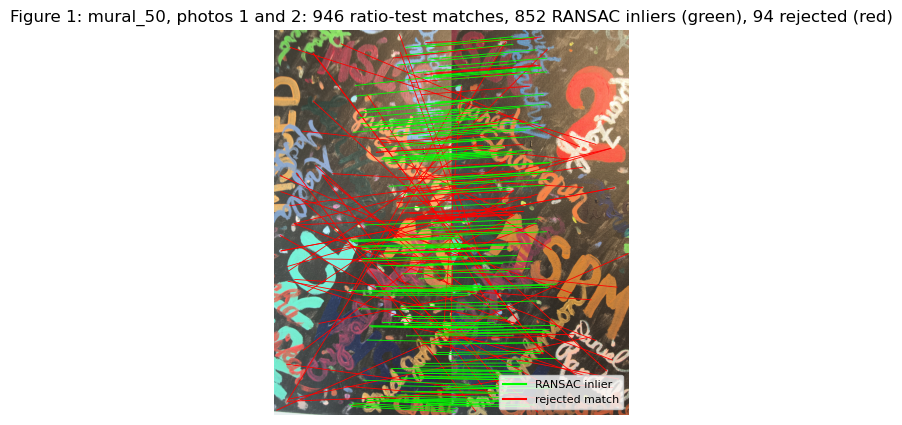

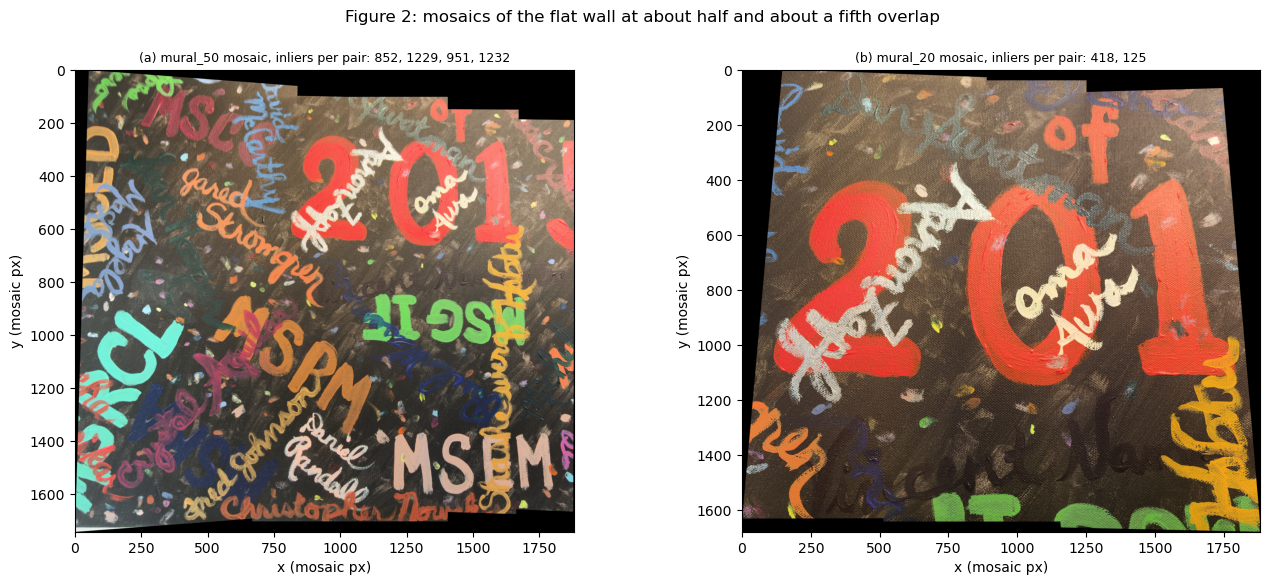

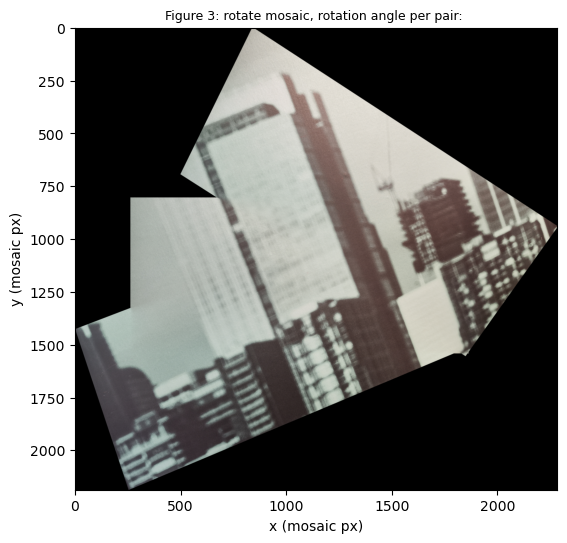

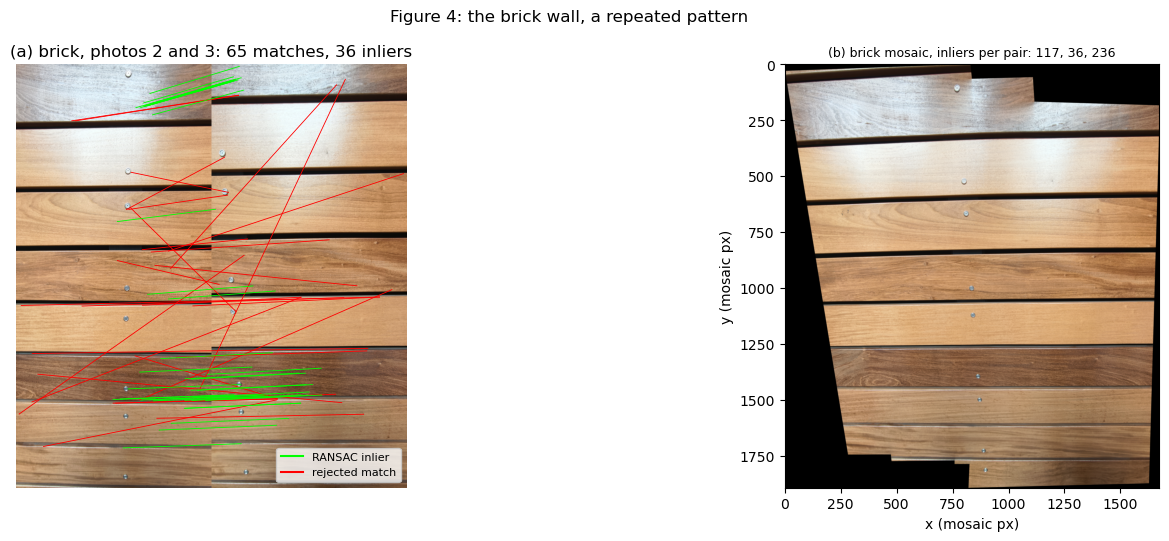

In [62]:
# %% Figures 1 to 4
s, p = sets['mural_50'], sets['mural_50']['pairs'][0]
fig, ax = plt.subplots(figsize=(13, 5))
draw_matches(s['images'][0], s['images'][1], p['p1'], p['p2'], p['inliers'], ax=ax,
             title=f"Figure 1: mural_50, photos 1 and 2: {p['n_matches']} ratio-test matches, "
                   f"{p['n_inliers']} RANSAC inliers (green), {p['n_matches'] - p['n_inliers']} rejected (red)")
match_legend(ax)
savefig(fig, 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, name, tag in zip(axes, ('mural_50', 'mural_20'), 'ab'):
    s = sets[name]
    inl = ', '.join(str(p['n_inliers']) for p in s['pairs'])
    if s['mosaic'] is not None:
        show_mosaic(ax, s['mosaic'], f'({tag}) {name} mosaic, inliers per pair: {inl}')
    else:
        ax.set_title(f"({tag}) {name}: {s['error']}")
fig.suptitle('Figure 2: mosaics of the flat wall at about half and about a fifth overlap')
savefig(fig, 2)

fig, ax = plt.subplots(figsize=(14, 6))
angles = ', '.join(f'{r[1]:.1f} deg' for r in rot)
if sets['rotate']['mosaic'] is not None:
    show_mosaic(ax, sets['rotate']['mosaic'], f'Figure 3: rotate mosaic, rotation angle per pair: {angles}')
else:
    ax.set_title(f"Figure 3: rotate mosaic failed: {sets['rotate']['error']}")
savefig(fig, 3)

s = sets['brick']
k = int(np.argmin([p['n_inliers'] for p in s['pairs']]))       # the hardest pair shows the most
p = s['pairs'][k]
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
draw_matches(s['images'][k], s['images'][k + 1], p['p1'], p['p2'], p['inliers'], ax=axes[0],
             title=f"(a) brick, photos {k + 1} and {k + 2}: {p['n_matches']} matches, {p['n_inliers']} inliers")
match_legend(axes[0])
if s['mosaic'] is not None:
    show_mosaic(axes[1], s['mosaic'], '(b) brick mosaic, inliers per pair: ' +
                ', '.join(str(q['n_inliers']) for q in s['pairs']))
else:
    axes[1].axis('off')
    axes[1].set_title(f"(b) brick mosaic failed: {s['error']}")
fig.suptitle('Figure 4: the brick wall, a repeated pattern')
savefig(fig, 4)


In [63]:
# %% Question 1 and Question 2 numbers
p1, p2, H_true, _ = test_points()
grid_pts = np.array([[x, y] for x in np.linspace(0, 1600, 9) for y in np.linspace(0, 1200, 7)])
for norm in (True, False):
    Hq = fit_homography(p1, p2, normalize=norm)
    e = np.linalg.norm(project(Hq, grid_pts) - project(H_true, grid_pts), axis=1)
    print(f"Q1 normalize={norm}: mean {e.mean():.3f} px, worst {e.max():.3f} px, "
          f"cond(A) {dlt_condition(p1, p2, normalize=norm):.3e}")

for thr in (0.5, 3.0, 10.0):
    s_thr = analyze_set('mural_50', threshold=thr)
    print(f"Q2 threshold {thr} px: inliers {[q['n_inliers'] for q in s_thr['pairs']]}, "
          f"RMS {[round(q['rms'], 2) for q in s_thr['pairs']]} px, tries {[q['tries'] for q in s_thr['pairs']]}")
    if s_thr['mosaic'] is not None:
        fig, ax = plt.subplots(figsize=(14, 5))
        show_mosaic(ax, s_thr['mosaic'], f'mural_50 mosaic with a RANSAC threshold of {thr} px')
        fig.savefig(FIG / f'q2_threshold_{thr}.png', dpi=120, bbox_inches='tight')
        plt.close(fig)


Q1 normalize=True: mean 0.128 px, worst 0.280 px, cond(A) 2.121e+03
Q1 normalize=False: mean 0.130 px, worst 0.304 px, cond(A) 1.068e+09
Q2 threshold 0.5 px: inliers [202, 429, 312, 431], RMS [0.33, 0.33, 0.31, 0.3] px, tries [5000, 1006, 1799, 1254]
Q2 threshold 3.0 px: inliers [852, 1229, 951, 1232], RMS [1.3, 1.19, 1.28, 1.18] px, tries [14, 19, 32, 6]
Q2 threshold 10.0 px: inliers [882, 1254, 1003, 1264], RMS [1.5, 1.3, 1.47, 1.28] px, tries [6, 5, 5, 5]


## 4.4 The road from the Mustang's camera (Figure 5)

The camera's pose in `base_footprint` is $T = [R \mid t]$: a point $X_c$ in the camera frame is at $X_b = R X_c + t$ in `base_footprint`. So $X_c = R^T (X_b - t)$. A point on the ground has $X_b = (x, y, 0)$, and its pixel is $K X_c$ up to scale:

$$\begin{bmatrix} u' \\ v' \\ w' \end{bmatrix} = K \left( R^T \begin{bmatrix} x \\ y \\ 0 \end{bmatrix} - R^T t \right) = K \begin{bmatrix} r'_1 & r'_2 & -R^T t \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

where $r'_1$ and $r'_2$ are the first two columns of $R^T$. The ground's z coordinate is zero, so the third column of $R^T$ drops out, and what is left is a homography from the road to the image. Write `ground_homography`, and run its test.

Then make Figure 5 from one frame on a straight street with lane markings, with the nominal pose from `fs['base_T_cam']`: draw the ground grid on the frame with `draw_ground_grid`, and show its bird's-eye view from `make_bev` next to it.

The camera's intrinsics deserve a look. In `camera.json`, compare `K[0][0]` with `K[1][1]`: the sensor's pixels are square, so the two should agree within about 0.2 percent. Make the bird's-eye view of the same frame with `load_frame(fs, i, undistort=False)` too, and compare the lane lines. Question 6 asks which you trust.

| Figure | Content |
|---|---|
| 5 | One frame with the ground grid drawn on it, and its bird's-eye view, side by side |

In [64]:
# %% Part 4.4: ground_homography
def ground_homography(K, base_T_cam):
    """The homography that maps a point (x, y) on the ground, z = 0 in base_footprint, to its
    image pixel: (u, v, 1) ~ H (x, y, 1).

    H is left at the scale where w' is the point's depth in front of the camera, which is
    positive for ground ahead. Dividing by H[2, 2] would flip that sign, because base_footprint
    itself is behind the camera, and frame_weight and GroundMap.add rely on it."""
    T = np.asarray(base_T_cam, float)
    Rt = T[:3, :3].T
    return np.asarray(K, float) @ np.column_stack([Rt[:, 0], Rt[:, 1], -Rt @ T[:3, 3]])


In [43]:
try:
    T_test = np.eye(4)
    T_test[:3, :3] = rot_y(4.0) @ np.array([[0, 0, 1], [-1, 0, 0], [0, -1, 0.0]])  # forward, 4 deg down
    T_test[:3, 3] = (1.9, 0.15, 1.75)
    K_test = np.array([[2900.0, 0, 612.0], [0, 2900.0, 486.0], [0, 0, 1]])
    Hg = ground_homography(K_test, T_test)
    rng = np.random.default_rng(3)
    ground = np.column_stack([rng.uniform(10, 25, 50), rng.uniform(-4, 4, 50), np.zeros(50)])
    cam = (ground - T_test[:3, 3]) @ T_test[:3, :3]          # R^T (p - t), one point per row
    pix = cam @ K_test.T
    pix = pix[:, :2] / pix[:, 2:3]
    print(f'ground_homography against a full 3D projection: largest difference '
          f'{np.abs(project(Hg, ground[:, :2]) - pix).max():.1e} px')
    u, v = project(Hg, [[20.0, 0.15]])[0]
    print(f'a point 20 m ahead, straight in front of the camera: pixel ({u:.0f}, {v:.0f}). It should be at the '
          f'center column, and {2900 * math.tan(math.atan(1.75 / 18.1) - math.radians(4)):.0f} px below the center row')
except NotImplementedError as err:
    print(err)

ground_homography against a full 3D projection: largest difference 4.5e-13 px
a point 20 m ahead, straight in front of the camera: pixel (612, 563). It should be at the center column, and 77 px below the center row


fx 2881.9, fy 2914.5: they differ by 1.12 percent; D = [-0.1432, 0.9996, -0.0052, -0.0089, 0.0]
Figure 5 only: using image frame 973 without claiming RTK synchronization
Q5 and Q7, URDF pose:
  at 10 m: 1.3 cm per pixel row; a 0.1 deg pitch error moves the ground 6.9 cm
  at 19 m: 5.8 cm per pixel row; a 0.1 deg pitch error moves the ground 29.2 cm


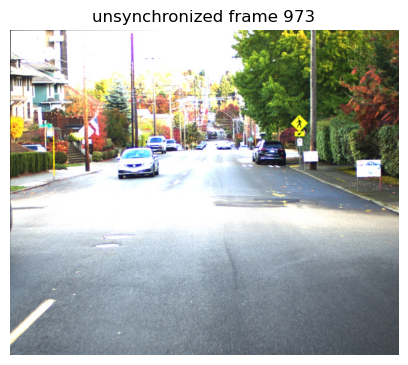

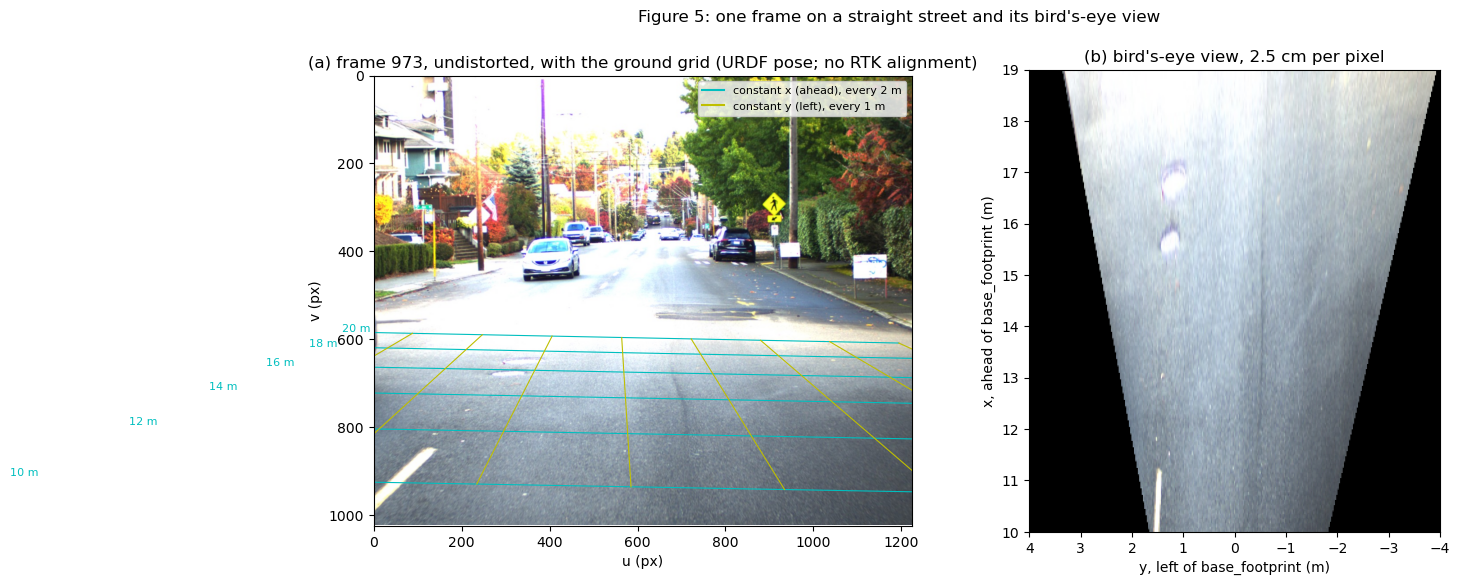

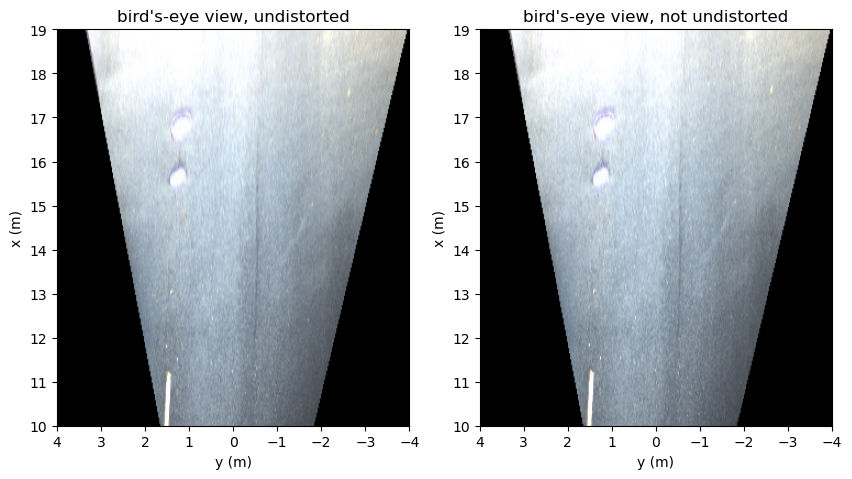

In [65]:
# %% Part 4.4: Figure 5
grid = bev_grid()
Hg_nom = ground_homography(fs['K'], fs['base_T_cam'])
Kc = fs['K']
print(f"fx {Kc[0, 0]:.1f}, fy {Kc[1, 1]:.1f}: they differ by {100 * abs(Kc[0, 0] / Kc[1, 1] - 1):.2f} percent; "
      f"D = {np.round(fs['D'], 4).tolist()}")

# Frame timestamps do not align with Lab 4 car data. Do not infer poses/speeds here.
# For Figure 5, select an image-only representative frame for geometry visualization.
FIG5_FRAME = len(fs['files']) // 2
print(f"Figure 5 only: using image frame {FIG5_FRAME} without claiming RTK synchronization")
show([load_frame(fs, FIG5_FRAME)], [f'unsynchronized frame {FIG5_FRAME}'], cols=1, size=5)

img5 = load_frame(fs, FIG5_FRAME)
bev5, _ = make_bev(img5, Hg_nom, grid)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.2, 1]})
draw_ground_grid(img5, Hg_nom, ax=axes[0])
axes[0].axis('on')
axes[0].set_xlabel('u (px)')
axes[0].set_ylabel('v (px)')
axes[0].legend(handles=[Line2D([], [], color='c', label='constant x (ahead), every 2 m'),
                        Line2D([], [], color='y', label='constant y (left), every 1 m')], loc='upper right', fontsize=8)
axes[0].set_title(f'(a) frame {FIG5_FRAME}, undistorted, with the ground grid (URDF pose; no RTK alignment)')
axes[1].imshow(bev5, extent=(4, -4, 10, 19))
axes[1].set_xlabel('y, left of base_footprint (m)')
axes[1].set_ylabel('x, ahead of base_footprint (m)')
axes[1].set_title('(b) bird\'s-eye view, 2.5 cm per pixel')
fig.suptitle('Figure 5: one frame on a straight street and its bird\'s-eye view')
savefig(fig, 5)

bev5_raw, _ = make_bev(load_frame(fs, FIG5_FRAME, undistort=False), Hg_nom, grid)
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, im, t in zip(axes, (bev5, bev5_raw), ('undistorted', 'not undistorted')):
    ax.imshow(im, extent=(4, -4, 10, 19))
    ax.set_xlabel('y (m)')
    ax.set_ylabel('x (m)')
    ax.set_title(f'bird\'s-eye view, {t}')
fig.savefig(FIG / 'q5_undistort_compare.png', dpi=120, bbox_inches='tight')


def ground_numbers(T_cam, y=None, dpitch=0.1):
    """cm of road per pixel row, and ground shift from a pitch error, at 10 m and 19 m ahead."""
    y = float(T_cam[1, 3]) if y is None else y
    H0 = ground_homography(fs['K'], T_cam)
    H1 = ground_homography(fs['K'], adjust_camera(T_cam, pitch_down_deg=dpitch))
    for x in (10.0, 19.0):
        v0, v1 = project(H0, [[x - 0.05, y], [x + 0.05, y]])[:, 1]
        row_cm = 100 * 0.1 / abs(v1 - v0)
        pix = project(H0, [[x, y]])
        x_err = project(np.linalg.inv(H1), pix)[0, 0]
        print(f'  at {x:.0f} m: {row_cm:.1f} cm per pixel row; a {dpitch} deg pitch error moves the ground '
              f'{100 * abs(x_err - x):.1f} cm')


print('Q5 and Q7, URDF pose:')
ground_numbers(fs['base_T_cam'])


> **STOP for Team 3 after Figure 5 (until data are corrected).** The distributed camera frame set is -1133.596 to -744.4 seconds on the existing `Lab4/data/car/car_drive.npz` time axis. The alternative `car_drive_2.npz` is -698.818 seconds. Consequently the frame set and RTK/VN-100 bag have **not** been verified as the same drive. Parts 4.5–4.8, Figures 6–10, and the final results table must not be represented as measured until the correct original Team 3 car files/frame-set are obtained from staff. Do **not** shift timestamps just to make checks pass.


## 4.5 Placing a frame on the map

To add a frame to a `GroundMap`, you need the homography from map pixels to that frame's image pixels. It is a chain of three maps:

1. **Map pixels to UTM.** Pixel (col, row) is at east $= e_0 + r \cdot \text{col}$ and north $= n_0 - r \cdot \text{row}$, with $e_0$, $n_0$, and $r$ the map's `e0`, `n0`, and `res`
2. **UTM to `base_footprint`.** With the car at $(E, N)$ and heading $\psi$, clockwise from grid north, a point $(e, n)$ is at $x = (e - E)\sin\psi + (n - N)\cos\psi$ ahead of the car and $y = -(e - E)\cos\psi + (n - N)\sin\psi$ to its left
3. **`base_footprint` to the image.** Your ground homography from Part 4.4

Write each of the first two as a 3 × 3 matrix, and return the product of all three, in the right order. Run its test, which uses the identity as the ground homography so that you can check the first two steps on their own.

Each frame's pose comes from `poses_at(track, t)`, at the frame's time on your laptop's clock. For now that is `t_lap = fs['t'] - L`. Part 4.6 finds out how late the camera is, and corrects it.

In [45]:
# %% Part 4.5: map_to_image
def map_to_image(H_ground, pose, gmap):
    """The homography from GroundMap pixels (col, row, 1) to image pixels, for a frame taken
    with base_footprint at pose = (east, north, heading clockwise from grid north, radians)."""
    E, N, psi = (float(v) for v in pose)
    r = float(gmap.res)
    map_to_utm = np.array([[r, 0, gmap.e0], [0, -r, gmap.n0], [0, 0, 1.0]])
    s, c = math.sin(psi), math.cos(psi)
    utm_to_base = np.array([[s, c, -E * s - N * c],
                            [-c, s, E * c - N * s],
                            [0, 0, 1.0]])
    return np.asarray(H_ground, float) @ utm_to_base @ map_to_utm


In [46]:
try:
    class _Map:
        e0, n0, res = 548000.0, 5278000.0, 0.05
    pose = (548031.2, 5277962.7, math.radians(118.0))
    Hg = np.eye(3)                       # the identity: then map_to_image maps map pixels to (x, y)
    Hm = map_to_image(Hg, pose, _Map)
    # a point 15 m ahead and 2 m to the left of the car, worked out by hand
    psi = pose[2]
    e = pose[0] + 15 * math.sin(psi) - 2 * math.cos(psi)
    n = pose[1] + 15 * math.cos(psi) + 2 * math.sin(psi)
    col, row = (e - _Map.e0) / _Map.res, (_Map.n0 - n) / _Map.res
    print('map pixel of a point 15 m ahead and 2 m left, mapped to (x, y):', project(Hm, [[col, row]]).round(4)[0],
          ' expected [15, 2]')
except NotImplementedError as err:
    print(err)

map pixel of a point 15 m ahead and 2 m left, mapped to (x, y): [15.  2.]  expected [15, 2]


## 4.6 Calibrating the camera from the road (Figures 6 and 7)

The pose in the URDF is the camera's pose as someone measured or guessed it. At 15 m ahead of the camera, a pitch error of 0.1 degrees moves the ground by about 23 cm, and the camera's timing is unknown. You can measure both from the drive itself, because the road moves through the camera's view exactly as the car moves.

### Visual odometry from the road

When the car moves from frame $a$ to frame $b$, the road in $b$'s bird's-eye view is the road in $a$'s, moved and turned the other way. Match the two views, keep the matches RANSAC agrees with, and fit the rigid motion between them in meters:

1. Match the two views with `sift_matches`, passing both masks, and find the inliers with your `ransac_homography`, with a threshold of 2 pixels. Return NaNs if fewer than `min_inliers` remain
2. Turn the inlier pixels into ground coordinates in meters with the grid's `G`: $(x, y, 1) = G\,(\text{col}, \text{row}, 1)$
3. Fit the rotation $R$ and translation $t$ with $q_b \approx R\, q_a + t$ by least squares, the Kabsch method in 2D: subtract each set's centroid, form $C = \sum (q_a - \bar q_a)(q_b - \bar q_b)^T$, take $C = U S V^T$, and $R = V U^T$, with the last row of $V^T$ flipped if $\det R < 0$. Then $t = \bar q_b - R\,\bar q_a$
4. $q_b = R\,q_a + t$ maps ground from $a$'s view to $b$'s, so $b$'s `base_footprint` sits at $-R^T t$ in $a$'s, and the car turned left by $\theta = \operatorname{atan2}(R_{01}, R_{00})$

Why not read the motion straight off the homography? Its translation entries describe how the homography moves the point $(0, 0)$, which is `base_footprint` itself, 10 m behind the nearest ground the camera sees. A pitch error barely moves that point, so the homography would hide exactly the errors you are after. The rigid fit uses the matched road itself.

Write `bev_motion` and run its test. Then make bird's-eye views of every frame with the nominal pose (convert each frame to grayscale first, which saves memory), and run `bev_motion` on each pair of neighbors. A 10 minute drive takes a few minutes. Save the results with `np.savez`, so you do not have to compute them twice.

### When the camera took each frame

$\theta$ divided by the time between the frames is the camera's turn rate, positive to the left. Your VN-100's gyro z measured the same turns, positive to the right, because its z axis points down. So paste your `find_lag` from Lab 4 Part 5.6 into its cell, check it with the test, and run it with the VN-100 first, with its sign flipped, and the camera second, with each turn rate at the middle of its pair of frames:

```python
L_cam, r, lags, corr = find_lag(gyro_t, -gyro_z, t_mid, turn_rate, max_lag=1.0)
```

Keep the gyro times at least 1.5 s inside the camera's, so every lag finds data. $L_{cam}$ is how late each frame's time is: from here on, frame $i$ was taken at `t_lap[i] - L_cam`. Expect a correlation above 0.9 and a lag of a few tenths of a second at most.

Turn rate, not speed, is the right signal here, for a reason you will see below: braking pitches the camera, which changes the scale of the bird's-eye view, and so the speed the images give.

### Pitch and yaw

With the frame times corrected, compare the distance the images give with the distance RTK gives for the same pairs of frames, on pairs that are:

- **Straight:** the turn between the frames is under 0.3 degrees
- **Steady:** the car's acceleration, from `track_speed`, is under 0.3 m/s<sup>2</sup>, so the suspension holds the car level
- **Moving:** faster than 3 m/s

The ratio of the two distances is about 1 when the pitch is right. A camera pitched farther down than the URDF says makes the ground look farther away than it is, and the ratio comes out above 1. Take about 100 of these pairs, and for pitch corrections from -1 to 1 degree in steps of 0.25, make their bird's-eye views again with `adjust_camera(fs['base_T_cam'], pitch_down_deg=...)` and compute the median ratio. Your pitch correction is where the curve crosses 1.

With that pitch, a straight pair should move the road straight back in the view. The median of $\operatorname{atan2}(dy, dx)$ over the same pairs is how far the camera is turned to the right of where the URDF says it points, so your yaw correction is minus that median. Check that it brings the median to about zero.

Last, with both corrections, compute the ratio for every straight, moving pair, steady or not, and plot it against the acceleration. When the car brakes, its nose dips. The slope of a line through these points, divided by the slope of your pitch curve near 1, is how many degrees the camera pitches per m/s<sup>2</sup> of braking.

| Figure | Content |
|---|---|
| 6 | (a) The VN-100's turn rate, sign flipped, and the camera's turn rate shifted by $L_{cam}$, against laptop time, with a zoom on one turn; (b) the correlation against the lag, with its peak marked |
| 7 | (a) The median ratio against the pitch correction, with your correction marked; (b) histograms of the direction of motion on straight pairs, before and after the yaw correction; (c) the ratio against the acceleration, with your line |

In [47]:
# %% Part 4.6: bev_motion
def bev_motion(bev_a, bev_b, mask_a, mask_b, grid, min_inliers=25):
    """How base_footprint moved between two frames, from their bird's-eye views.

    Returns (dx, dy, dtheta, n_inliers): the position of frame b's base_footprint in frame
    a's, in meters, the turn from a to b in radians (positive to the left), and the number of
    RANSAC inliers. Returns NaNs when fewer than min_inliers matches agree.
    """
    p_a, p_b = sift_matches(bev_a, bev_b, mask1=mask_a, mask2=mask_b)
    if len(p_a) < max(min_inliers, 4):
        return np.nan, np.nan, np.nan, 0
    H, inl, _ = ransac_homography(p_a, p_b, threshold=2.0)
    n = int(inl.sum())
    if H is None or n < min_inliers:
        return np.nan, np.nan, np.nan, n
    G = grid[0]
    qa, qb = project(G, p_a[inl]), project(G, p_b[inl])
    ca, cb = qa.mean(axis=0), qb.mean(axis=0)
    C = (qa - ca).T @ (qb - cb)
    U, _, Vt = np.linalg.svd(C)
    R = Vt.T @ U.T
    if np.linalg.det(R) < 0:
        Vt[-1] *= -1
        R = Vt.T @ U.T
    t = cb - R @ ca
    pos = -R.T @ t
    return float(pos[0]), float(pos[1]), math.atan2(R[0, 1], R[0, 0]), n


In [48]:
def test_bevs(dx=1.8, dy=0.05, dtheta_deg=1.5, seed=4):
    """Two bird's-eye views of a textured ground patch, with base_footprint moved by (dx, dy)
    and turned by dtheta between them."""
    rng = np.random.default_rng(seed)
    res_t = 0.02
    tex = cv2.GaussianBlur(rng.normal(128, 160, (1500, 1500)).astype(np.float32), (0, 0), 1.5)
    tex += cv2.resize(rng.normal(0, 25, (60, 60)).astype(np.float32), (1500, 1500), interpolation=cv2.INTER_CUBIC)
    for _ in range(60):
        c = tuple(int(v) for v in rng.integers(0, 1500, 2))
        cv2.circle(tex, c, int(rng.integers(5, 25)), float(rng.integers(0, 255)), -1)
    tex = np.clip(tex, 0, 255).astype(np.uint8)
    tex = np.dstack([tex] * 3)
    to_tex = np.array([[1 / res_t, 0, 750], [0, -1 / res_t, 750], [0, 0, 1.0]])   # world (m) -> texture px
    grid = bev_grid()
    G = grid[0]
    out = []
    th = math.radians(dtheta_deg)
    for (px, py, pt) in ((0.0, 0.0, 0.0), (dx, dy, th)):
        base_to_world = np.array([[math.cos(pt), -math.sin(pt), px - 14], [math.sin(pt), math.cos(pt), py], [0, 0, 1]])
        M = to_tex @ base_to_world @ G
        bev = cv2.warpPerspective(tex, M, grid[1], flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)
        out.append(bev)
    mask = np.full(out[0].shape[:2], 255, np.uint8)
    return out[0], out[1], mask, grid


try:
    a, b, m, grid = test_bevs()
    dx, dy, dth, n = bev_motion(a, b, m, m, grid)
    print(f'dx {dx:.3f} m (true 1.800), dy {dy:.3f} m (true 0.050), turn {math.degrees(dth):.2f} deg '
          f'(true 1.50), {n} inliers')
except NotImplementedError as err:
    print(err)

dx 1.800 m (true 1.800), dy 0.050 m (true 0.050), turn 1.50 deg (true 1.50), 3006 inliers


In [49]:
# %% Part 4.6: find_lag, with the same contract as Lab 4 Part 5.6
def find_lag(t_lap, w_lap, t_car, w_car, max_lag=60.0, rate=100.0):
    """L such that a moment at time t in the first series is at time t + L in the second.
    Returns (L, best correlation, the candidate lags, the correlation at each lag)."""
    t1, w1 = np.asarray(t_lap, float), np.asarray(w_lap, float)
    t2, w2 = np.asarray(t_car, float), np.asarray(w_car, float)
    k1, k2 = np.isfinite(t1) & np.isfinite(w1), np.isfinite(t2) & np.isfinite(w2)
    t1, w1, t2, w2 = t1[k1], w1[k1], t2[k2], w2[k2]
    o1, o2 = np.argsort(t1), np.argsort(t2)
    t1, w1, t2, w2 = t1[o1], w1[o1], t2[o2], w2[o2]
    lo = max(t1[0], t2[0] + max_lag)
    hi = min(t1[-1], t2[-1] - max_lag)
    if hi - lo < 10 * max(max_lag, 1.0):
        raise ValueError(f'the series overlap for only {hi - lo:.1f} s inside a lag of {max_lag} s')
    grid = np.arange(lo, hi, 1.0 / rate)
    a = np.interp(grid, t1, w1)
    a = (a - a.mean()) / (a.std() + 1e-12)
    lags = np.arange(-max_lag, max_lag + 0.5 / rate, 1.0 / rate)
    corr = np.empty(lags.size)
    for j, lag in enumerate(lags):
        b = np.interp(grid + lag, t2, w2)
        corr[j] = np.mean(a * (b - b.mean())) / (b.std() + 1e-12)
    j = int(np.argmax(corr))
    L = lags[j]
    if 0 < j < lags.size - 1:                          # parabola through the peak and its neighbors
        y0, y1, y2 = corr[j - 1], corr[j], corr[j + 1]
        den = y0 - 2 * y1 + y2
        if den < 0:
            L += 0.5 * (y0 - y2) / den / rate
    return float(L), float(corr[j]), lags, corr


In [50]:
try:
    rng = np.random.default_rng(6)
    t_a = np.arange(0, 120, 1.0)
    v = np.clip(np.convolve(rng.normal(0, 3, t_a.size), np.ones(9) / 9, 'same') * 3 + 6, 0, 12)
    s_a = CubicSpline(t_a, v)
    t_b = np.arange(2, 118, 0.2) + rng.normal(0, 0.003, 580)
    v_b = s_a(t_b - 0.137) + rng.normal(0, 0.2, t_b.size)        # the second series is 0.137 s late
    t_grid = np.arange(4, 116, 0.01)
    L, r, lags, corr = find_lag(t_grid, s_a(t_grid), t_b, v_b, max_lag=1.0)
    print(f'L = {L:.3f} s (true 0.137), correlation {r:.3f}')
except NotImplementedError as err:
    print(err)

L = 0.141 s (true 0.137), correlation 0.998


In [51]:
# %% Part 4.6: odometry on every pair of neighbors, computed once and saved
_dt = np.diff(fs['t'])


def run_odometry(T_cam, path, frames=None):
    path = Path(path)
    if path.exists():
        z = np.load(path)
        if np.allclose(z['T_cam'], T_cam):
            print(f'read {path.name}')
            return z['motions']
    Hg = ground_homography(fs['K'], T_cam)
    frames = np.arange(len(fs['files'])) if frames is None else frames
    motions = np.full((len(fs['files']) - 1, 4), np.nan)
    prev = None
    for n, i in enumerate(frames):
        gray = cv2.cvtColor(load_frame(fs, i), cv2.COLOR_RGB2GRAY)
        cur = (i, *make_bev(gray, Hg, grid))
        if prev is not None and prev[0] == i - 1 and _dt[i - 1] < 0.5:
            motions[i - 1] = bev_motion(prev[1], cur[1], prev[2], cur[2], grid)
        prev = cur
        if n % 500 == 0:
            print(f'  {n} of {len(frames)} frames')
    np.savez(path, motions=motions, T_cam=T_cam)
    return motions


vo_nom = run_odometry(fs['base_T_cam'], LAB5 / 'analysis' / 'vo_nominal.npz')
n_motion = int(np.isfinite(vo_nom[:, 0]).sum())
print(f"{len(fs['files'])} frames, {len(vo_nom)} pairs of neighbors, {n_motion} with a motion "
      f"({100 * n_motion / len(vo_nom):.1f} percent)")


  0 of 1947 frames
  500 of 1947 frames
  1000 of 1947 frames
  1500 of 1947 frames
1947 frames, 1946 pairs of neighbors, 1480 with a motion (76.1 percent)


In [52]:
# %% Part 4.6: the camera's lag, Figure 6
t_mid = 0.5 * (t_lap[:-1] + t_lap[1:])
turn_rate = vo_nom[:, 2] / _dt
okr = np.isfinite(turn_rate) & (np.abs(turn_rate) < 1.0)
if okr.sum() < 20:
    raise RuntimeError(
        f"Only {okr.sum()} valid VO turn-rate samples; "
        "cannot reliably estimate camera lag."
    )
gt, gz = lab4['gyro']['t'], lab4['gyro']['z']
keep = (gt > t_mid[okr][0] + 1.5) & (gt < t_mid[okr][-1] - 1.5)
L_cam, r_cam, lags, corr = find_lag(gt[keep], -gz[keep], t_mid[okr], turn_rate[okr], max_lag=1.0)
print(f"L_cam = {L_cam:.3f} s, correlation {r_cam:.3f}; GPS/DGPS reference (not RTK)")

t_turn = gt[keep][np.argmax(np.abs(gz[keep]))]
fig = plt.figure(figsize=(14, 8))
ax1 = fig.add_subplot(2, 2, (1, 2))
ax2 = fig.add_subplot(2, 2, 3)
ax3 = fig.add_subplot(2, 2, 4)
for ax in (ax1, ax2):
    ax.plot(gt[keep], -np.degrees(gz[keep]), 'k', lw=0.6, label='VN-100 gyro z, sign flipped')
    ax.plot(t_mid[okr] - L_cam, np.degrees(turn_rate[okr]), 'o-', color='tab:orange', ms=2, lw=0.6,
            label=f'camera, from bird\'s-eye odometry, shifted by L_cam = {L_cam:.3f} s')
    ax.set_xlabel('laptop time (s)')
    ax.set_ylabel('turn rate, left positive (deg/s)')
    ax.legend(fontsize=8)
ax1.set_title('(a) turn rate over the drive')
ax2.set_xlim(t_turn - 8, t_turn + 8)
ax2.set_title('(a) zoom on one turn')
ax3.plot(lags, corr, label='correlation')
ax3.axvline(L_cam, color='r', ls='--', label=f'peak: {L_cam:.3f} s, r = {r_cam:.3f}')
ax3.set_xlabel('lag (s)')
ax3.set_ylabel('correlation coefficient')
ax3.set_title('(b) correlation against the lag')
ax3.legend(fontsize=8)
fig.suptitle('Figure 6: the camera\'s time delay from its turn rate')
fig.tight_layout()
savefig(fig, 6)


TypeError: 'NoneType' object is not subscriptable

In [ ]:
# %% Part 4.6: pitch and yaw, Figure 7
t_cor = t_lap - L_cam
pa, va = poses_at(track, t_cor[:-1])
pb, vb = poses_at(track, t_cor[1:])
d_rtk = np.hypot(pb[:, 0] - pa[:, 0], pb[:, 1] - pa[:, 1])
tm = 0.5 * (t_cor[:-1] + t_cor[1:])
spd = track_speed(track, tm)
acc = (track_speed(track, tm + 0.25) - track_speed(track, tm - 0.25)) / 0.5
straight = np.abs(np.degrees(vo_nom[:, 2])) < 0.3
moving = (spd > 3) & va & vb & (_dt < 0.5) & np.isfinite(vo_nom[:, 0])
steady = np.abs(acc) < 0.3
pool = np.flatnonzero(straight & moving & steady)
sel = np.sort(np.random.default_rng(0).choice(pool, min(100, pool.size), replace=False))
print(f'{pool.size} straight, steady, moving pairs; using {sel.size}')


def motions_for(pairs, T_cam):
    Hg = ground_homography(fs['K'], T_cam)
    out = np.full((len(pairs), 4), np.nan)
    for k, i in enumerate(pairs):
        a = make_bev(cv2.cvtColor(load_frame(fs, i), cv2.COLOR_RGB2GRAY), Hg, grid)
        b = make_bev(cv2.cvtColor(load_frame(fs, i + 1), cv2.COLOR_RGB2GRAY), Hg, grid)
        out[k] = bev_motion(a[0], b[0], a[1], b[1], grid)
    return out


def med_ratio(mo, pairs):
    return float(np.nanmedian(np.hypot(mo[:, 0], mo[:, 1]) / d_rtk[pairs]))


pitches = np.arange(-1.0, 1.001, 0.25)
med = np.array([med_ratio(motions_for(sel, adjust_camera(fs['base_T_cam'], pitch_down_deg=p)), sel)
                for p in pitches])
cross = np.flatnonzero((med[:-1] - 1) * (med[1:] - 1) <= 0)
if cross.size:
    j = cross[0]
    pitch_corr = float(pitches[j] + (1 - med[j]) * (pitches[j + 1] - pitches[j]) / (med[j + 1] - med[j]))
    curve_slope = float((med[j + 1] - med[j]) / (pitches[j + 1] - pitches[j]))
else:
    c1, c0 = np.polyfit(pitches, med, 1)
    pitch_corr, curve_slope = float((1 - c0) / c1), float(c1)
    print('the ratio never crosses 1 in the sweep: the correction comes from a line through the sweep')
ratio_before = float(med[np.argmin(np.abs(pitches))])

mo_p = motions_for(sel, adjust_camera(fs['base_T_cam'], pitch_down_deg=pitch_corr))
dir_before = np.degrees(np.arctan2(mo_p[:, 1], mo_p[:, 0]))
yaw_corr = -float(np.nanmedian(dir_before))
T_corr = adjust_camera(fs['base_T_cam'], pitch_down_deg=pitch_corr, yaw_left_deg=yaw_corr)
mo_c = motions_for(sel, T_corr)
dir_after = np.degrees(np.arctan2(mo_c[:, 1], mo_c[:, 0]))
ratio_after = med_ratio(mo_c, sel)
print(f'pitch correction {pitch_corr:+.3f} deg (down), yaw correction {yaw_corr:+.3f} deg (left); '
      f'median direction {np.nanmedian(dir_before):+.3f} -> {np.nanmedian(dir_after):+.3f} deg; '
      f'median ratio {ratio_before:.4f} -> {ratio_after:.4f}')

vo_cor = run_odometry(T_corr, LAB5 / 'analysis' / 'vo_corrected.npz')
all_pairs = np.flatnonzero((np.abs(np.degrees(vo_cor[:, 2])) < 0.3) & moving & np.isfinite(vo_cor[:, 0]))
ratio_all = np.hypot(vo_cor[all_pairs, 0], vo_cor[all_pairs, 1]) / d_rtk[all_pairs]
good = np.isfinite(ratio_all) & (np.abs(ratio_all - 1) < 0.5)
slope_acc, icpt_acc = np.polyfit(acc[all_pairs][good], ratio_all[good], 1)
pitch_per_mps2 = float(slope_acc / curve_slope)
print(f'ratio against acceleration: slope {slope_acc:+.4f} per m/s^2, so {pitch_per_mps2:+.3f} deg of pitch '
      f'per m/s^2 (pitch curve slope {curve_slope:+.3f} per deg)')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(pitches, med, 'o-', label='median ratio, steady straight pairs')
axes[0].axhline(1, color='gray', ls=':', label='ratio 1')
axes[0].axvline(pitch_corr, color='r', ls='--', label=f'correction {pitch_corr:+.2f} deg')
axes[0].set_xlabel('pitch correction, nose down (deg)')
axes[0].set_ylabel('image distance / RTK distance')
axes[0].set_title('(a) median ratio against the pitch correction')
axes[0].legend(fontsize=8)
bins = np.linspace(-6, 6, 49)
axes[1].hist(dir_before[np.isfinite(dir_before)], bins, alpha=0.6, label=f'before, median {np.nanmedian(dir_before):+.2f} deg')
axes[1].hist(dir_after[np.isfinite(dir_after)], bins, alpha=0.6, label=f'after, median {np.nanmedian(dir_after):+.2f} deg')
axes[1].set_xlabel('direction of motion, atan2(dy, dx) (deg)')
axes[1].set_ylabel('pairs (count)')
axes[1].set_title(f'(b) straight pairs, yaw correction {yaw_corr:+.2f} deg')
axes[1].legend(fontsize=8)
axes[2].plot(acc[all_pairs][good], ratio_all[good], '.', ms=3, alpha=0.5, label='straight moving pairs')
xa = np.linspace(np.nanmin(acc[all_pairs][good]), np.nanmax(acc[all_pairs][good]), 10)
axes[2].plot(xa, icpt_acc + slope_acc * xa, 'r', label=f'fit: slope {slope_acc:+.4f} per m/s^2')
axes[2].set_xlabel('acceleration (m/s^2)')
axes[2].set_ylabel('image distance / RTK distance')
axes[2].set_title('(c) ratio against acceleration, both corrections')
axes[2].legend(fontsize=8)
fig.suptitle('Figure 7: pitch and yaw of the camera from the road')
fig.tight_layout()
savefig(fig, 7)

print('Q7, corrected pose:')
ground_numbers(T_corr)


## 4.7 A map of the street, and its error budget (Figures 8 and 9)

Pick a stretch of your drive 150 to 400 m long with lane markings and a crosswalk or a stop line. Build two maps of it at 10 cm per pixel with `GroundMap.around`:

- **Nominal:** the URDF pose, and frame times `t_lap`
- **Corrected:** your pitch and yaw corrections, and frame times `t_lap - L_cam`

For each frame, compute the ground homography once for the whole map, the weight with `frame_weight` once too, the frame's pose with `poses_at`, and add the frame with `map_to_image`. Skip frames whose pose `poses_at` marks invalid. Report the mean `spread` of each map.

Then zoom in. Choose a patch 20 to 40 m on a side, at 3 cm per pixel, that your route drove twice, in opposite directions if it can be: there the two passes check each other. If your route never drove a street twice, use a stop line you braked toward, where the car changed speed. Make five maps of the patch, each with the corrected camera and timing but one change:

- **Corrected,** with nothing changed
- **Time +0.2 s:** frame times 0.2 s later
- **No lever arm:** a track from `base_track(fix, 0.0, 0.0)`, as if the antenna sat on the rear axle
- **Heading +1 deg:** add one degree to every pose's heading
- **Pitch +0.5 deg:** the camera pitched another half degree down

Only frames whose pose is within about 25 m of the patch can see it, so add only those, and each map takes seconds. Report each map's mean spread.

| Figure | Content |
|---|---|
| 8 | The nominal and the corrected map of your stretch, side by side, with east and north in meters, equal axes, `base_footprint`'s track drawn on each, and each map's mean spread in its title |
| 9 | The five maps of your patch, with each one's mean spread in its title |

In [ ]:
# %% Part 4.7: maps, Figures 8 and 9
def build_map(frames, T_cam, t_frames, trk, heading_add_deg=0.0, gmap=None, res=0.10, near=None, radius=40.0):
    Hg = ground_homography(fs['K'], T_cam)
    weight = frame_weight(Hg, fs['size'])
    poses, valid = poses_at(trk, t_frames[frames])
    poses = poses.copy()
    poses[:, 2] += math.radians(heading_add_deg)
    if near is not None:
        valid &= np.hypot(poses[:, 0] - near[0], poses[:, 1] - near[1]) < radius
    if gmap is None:
        gmap = GroundMap.around(poses[valid], res=res)
    for k, i in enumerate(frames):
        if valid[k]:
            gmap.add(load_frame(fs, i), map_to_image(Hg, poses[k], gmap), weight)
    return gmap


def empty_like(g, res=None):
    return GroundMap((g.e0, g.e0 + g.w * g.res), (g.n0 - g.h * g.res, g.n0), g.res if res is None else res)


def mean_spread(g):
    return float(np.nanmean(g.spread()))


def plot_map(ax, g, t0, t1, trk, title):
    ax.imshow(g.image(), extent=g.extent())
    tt = np.linspace(t0, t1, 400)
    ax.plot(trk['e_spline'](tt), trk['n_spline'](tt), 'm', lw=0.8, label='base_footprint track')
    ax.set_aspect('equal')
    ax.set_xlim(g.extent()[:2])
    ax.set_ylim(g.extent()[2:])
    ax.set_xlabel('east, UTM (m)')
    ax.set_ylabel('north, UTM (m)')
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7, loc='upper right')


def path_length(t0, t1):
    tt = np.arange(t0, t1, 0.1)
    return float(np.sum(np.hypot(np.diff(track['e_spline'](tt)), np.diff(track['n_spline'](tt)))))


# The stretch: by default the 250 m of track that turns the least, which tends to be a marked street
STRETCH = None
if STRETCH is None:
    tt = np.arange(track['t'][0] + 2, track['t'][-1] - 2, 0.5)
    ss = np.concatenate([[0], np.cumsum(np.hypot(np.diff(track['e_spline'](tt)), np.diff(track['n_spline'](tt))))])
    hh = np.unwrap(poses_at(track, tt)[0][:, 2])
    best = None
    for a in range(len(tt)):
        b = np.searchsorted(ss, ss[a] + 250)
        if b >= len(tt):
            break
        turn = np.sum(np.abs(np.diff(hh[a:b + 1])))
        if best is None or turn < best[0]:
            best = (turn, tt[a], tt[b])
    STRETCH = (best[1], best[2])
print(f'stretch {STRETCH[0]:.1f} to {STRETCH[1]:.1f} s laptop time, {path_length(*STRETCH):.0f} m')

seg = np.flatnonzero((t_cor >= STRETCH[0]) & (t_cor <= STRETCH[1]))
map_cor = build_map(seg, T_corr, t_cor, track)
map_nom = build_map(seg, fs['base_T_cam'], t_lap, track, gmap=empty_like(map_cor))
spread_nom, spread_cor = mean_spread(map_nom), mean_spread(map_cor)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
plot_map(axes[0], map_nom, *STRETCH, track, f'(a) nominal: URDF pose, times t_lap; mean spread {spread_nom:.1f} gray levels')
plot_map(axes[1], map_cor, *STRETCH, track, f'(b) corrected: pitch, yaw, and L_cam; mean spread {spread_cor:.1f} gray levels')
fig.suptitle(f'Figure 8: ground map of a {path_length(*STRETCH):.0f} m stretch at 10 cm per pixel')
fig.tight_layout()
savefig(fig, 8)

# The patch: by default the spot driven twice with the most opposite headings, else the hardest braking
PATCH_CENTER, PATCH_SIDE = None, 30.0
if PATCH_CENTER is None:
    tt = np.arange(track['t'][0] + 2, track['t'][-1] - 2, 1.0)
    P, okp = poses_at(track, tt)
    best = None
    for a in range(len(tt)):
        far = (tt - tt[a] > 30) & okp & okp[a]
        d = np.hypot(P[:, 0] - P[a, 0], P[:, 1] - P[a, 1])
        dpsi = np.degrees(np.abs(np.angle(np.exp(1j * (P[:, 2] - P[a, 2])))))
        cand = np.flatnonzero(far & (d < 4) & (track_speed(track, tt) > 3) & (track_speed(track, tt[a]) > 3))
        if cand.size:
            b = cand[np.argmax(dpsi[cand])]
            if best is None or dpsi[b] > best[0]:
                best = (dpsi[b], a, b)
    if best is not None:
        PATCH_CENTER = (float(P[best[1], 0]), float(P[best[1], 1]))
        print(f'patch: driven at {tt[best[1]]:.0f} s and {tt[best[2]]:.0f} s, headings {best[0]:.0f} deg apart')
    else:
        a = int(np.nanargmin(np.where(okp, (track_speed(track, tt + 0.5) - track_speed(track, tt - 0.5)), np.nan)))
        e, n, psi = P[a]
        PATCH_CENTER = (float(e + 15 * math.sin(psi)), float(n + 15 * math.cos(psi)))
        print(f'no street driven twice: patch 15 m ahead of the hardest braking, at {tt[a]:.0f} s')
half = PATCH_SIDE / 2
patch = GroundMap((PATCH_CENTER[0] - half, PATCH_CENTER[0] + half),
                  (PATCH_CENTER[1] - half, PATCH_CENTER[1] + half), res=0.03)
everyone = np.arange(len(fs['files']))
track0 = base_track(fix, 0.0, 0.0)
variants = {
    'corrected': dict(T_cam=T_corr, t_frames=t_cor, trk=track),
    'time +0.2 s': dict(T_cam=T_corr, t_frames=t_cor + 0.2, trk=track),
    'no lever arm': dict(T_cam=T_corr, t_frames=t_cor, trk=track0),
    'heading +1 deg': dict(T_cam=T_corr, t_frames=t_cor, trk=track, heading_add_deg=1.0),
    'pitch +0.5 deg': dict(T_cam=adjust_camera(fs['base_T_cam'], pitch_down_deg=pitch_corr + 0.5,
                                               yaw_left_deg=yaw_corr), t_frames=t_cor, trk=track),
}
patch_maps, patch_spread = {}, {}
for name, kw in variants.items():
    patch_maps[name] = build_map(everyone, gmap=empty_like(patch), near=PATCH_CENTER, radius=half + 25, **kw)
    patch_spread[name] = mean_spread(patch_maps[name])
    print(f'  {name}: mean spread {patch_spread[name]:.2f}')

_near = poses_at(track, t_cor)
_sel = _near[1] & (np.hypot(_near[0][:, 0] - PATCH_CENTER[0], _near[0][:, 1] - PATCH_CENTER[1]) < half + 25)
v_patch = float(np.median(track_speed(track, t_cor[_sel]))) if _sel.any() else float('nan')
fig, axes = plt.subplots(1, 5, figsize=(26, 6))
for ax, (name, g) in zip(axes, patch_maps.items()):
    plot_map(ax, g, track['t'][0], track['t'][-1], variants[name]['trk'],
             f'{name}: mean spread {patch_spread[name]:.2f} gray levels')
fig.suptitle(f'Figure 9: a {PATCH_SIDE:.0f} m patch at 3 cm per pixel, one error at a time')
fig.tight_layout()
savefig(fig, 9)
print(f'Q8: median speed near the patch {v_patch:.1f} m/s, so 0.2 s is {0.2 * v_patch:.2f} m along the road; '
      f'1 deg of heading moves ground 15 m ahead by {15 * math.radians(1):.2f} m; the lever arm is '
      f'{math.hypot(X_A, Y_A):.2f} m')
ground_numbers(T_corr, dpitch=0.5)


## 4.8 The whole drive on one clock (Figure 10)

Every number so far came from one pair of sensors at a time. Now put them all together and look. If $L$, $L_{cam}$, your track, and your camera pose are right, the LiDAR points land on the lane lines, curbs, and parked cars they hit in every frame, while the car drives and while it turns. If one of them is wrong, you see which one, and in which direction.

1. Pick a window of one to two minutes of your drive, on your laptop's clock, with at least one turn and one stop, ideally the stretch you mapped in Part 4.7
2. Start a recording with `rerun_start()`, and log two versions of the camera with `log_drive`:
    - **nominal:** frame times `t_lap`, and the pose from the URDF, `fs['base_T_cam']`
    - **corrected:** frame times `t_lap - L_cam`, and the pose with your pitch and yaw corrections from Part 4.6
   
   Pass `lidar` and your $L$, your corrected map from Part 4.7 as `gmap`, and the window. With `every=2` it logs every second frame, which keeps the file near 150 MB
3. Add four curves with `log_series`, on your laptop's clock: the VN-100's turn rate with its sign flipped and the camera's turn rate shifted by $L_{cam}$, under `plots/turn_rate/`, both in degrees per second, and the RTK speed and the speed from the images, under `plots/speed/`. You computed all four in Part 4.6
4. Write the file with `rerun_save(LAB5 / 'analysis' / 'lab5_drive.rrd')`, and open it in a terminal with `python3 -m rerun ~/EECE5554/Lab5/analysis/lab5_drive.rrd`. Keep it out of Git: add `*.rrd` to your `.gitignore`

In the viewer, drag the time cursor along the bottom, or press play. The 3D view shows the track colored by fix quality, the LiDAR, and both cars with their camera frustums. Each camera view shows its frames with the LiDAR drawn on them, colored by how bright each return was: lane paint and signs come back bright and are drawn red, plain asphalt is blue, so the red points should sit right on the paint. `lidar_color='distance'` colors them by depth instead, which helps with curbs and parked cars. Hover over a point to read its pixel coordinates. Scroll to zoom.

Look at three moments: driving straight at speed, in the middle of a turn, and stopped. At each, compare the two camera views: where do the LiDAR points on a lane line, a curb, or a parked car sit, compared with the thing itself? Measure the offset in pixels, along and across the image, by hovering. Then look at the map view, where the car should stay on the road it is driving.

| Figure | Content |
|---|---|
| 10 | Two screenshots of the viewer: (a) the whole layout at a turn, with the corrected camera; (b) the nominal and the corrected camera views at the same moment, with the LiDAR drawn on them, at a moment where they differ clearly |

In [ ]:
# %% Part 4.8: Rerun recording for Figure 10
RERUN_WINDOW = None
if RERUN_WINDOW is None:
    best = None
    for t0 in np.arange(track['t'][0] + 5, track['t'][-1] - 95, 5.0):
        tt = np.arange(t0, t0 + 90, 0.5)
        sp = track_speed(track, tt)
        g = keep & (gt >= t0) & (gt <= t0 + 90)
        score = np.sum(np.abs(gz[g])) * (1.0 if np.sum(sp < 0.3) >= 4 else 0.3)
        if best is None or score > best[0]:
            best = (score, t0)
    RERUN_WINDOW = (float(best[1]), float(best[1] + 90))
print(f'Rerun window {RERUN_WINDOW[0]:.0f} to {RERUN_WINDOW[1]:.0f} s laptop time')

image_speed = np.hypot(vo_cor[:, 0], vo_cor[:, 1]) / _dt
t_speed = np.arange(*RERUN_WINDOW, 0.1)
rerun_start()
log_drive(fs, track, fix,
          {'nominal': (t_lap, fs['base_T_cam']), 'corrected': (t_cor, T_corr)},
          lidar=lidar, L=L, gmap=map_cor, window=RERUN_WINDOW, every=2)
log_series('plots/turn_rate/vn100', gt[keep], -np.degrees(gz[keep]), 'VN-100, sign flipped', [0, 0, 0])
log_series('plots/turn_rate/camera', t_mid[okr] - L_cam, np.degrees(turn_rate[okr]), 'camera', [220, 80, 40])
log_series('plots/speed/gps_dgps', t_speed, track_speed(track, t_speed), 'GPS/DGPS reference', [40, 160, 60])
log_series('plots/speed/images', t_mid - L_cam, image_speed, 'images', [40, 90, 220])
rerun_save(LAB5 / 'analysis' / 'lab5_drive.rrd')


## Results table

Report these numbers in a table in `Lab5/README.md`, and fill in the same numbers in the cell below, which writes `analysis/lab5_results.json`. The worked example shows the format.

| Quantity | Units |
|---|---|
| For each photo set: the photos, and the median matches, median inliers, RMS inlier error, and RANSAC tries per pair | count, px |
| The focal length from EXIF, at the reduced size | px |
| `rotate`: the rotation angle and the misfit of each pair, and the misfit of one `mural_50` pair | degrees, none |
| The frames, the pairs of neighbors, and the share with a motion | count, percent |
| $L$ from Lab 4, and the median RTK delay | s |
| The camera's lag $L_{cam}$, and its correlation | s, none |
| The pitch correction and the yaw correction | degrees |
| The median ratio on steady pairs, before and after both corrections | none |
| The slope of the ratio against acceleration, and the camera pitch per m/s<sup>2</sup> it means | 1/(m/s<sup>2</sup>), degrees/(m/s<sup>2</sup>) |
| The mean spread of the nominal and the corrected map of your stretch | gray levels |
| The mean spread of each of the five patch maps | gray levels |
| Figure 10: how far the LiDAR points sit from what they hit, along and across the image, in the nominal and the corrected view, while driving straight, in a turn, and stopped | px |

In [ ]:
# %% Results file and the README table
def med(name, key):
    v = [p[key] for p in sets[name]['pairs']]
    return float(np.nanmedian(v))


results = {
    'photos': {name: {'photos': len(sets[name]['images']), 'median_matches': med(name, 'n_matches'),
                      'median_inliers': med(name, 'n_inliers'), 'rms_px': med(name, 'rms'),
                      'tries': med(name, 'tries')} for name in SETS},
    'focal_px': float(K_photo[0, 0]),
    'rotate_angles_deg': [float(r[1]) for r in rot],
    'rotate_misfits': [float(r[2]) for r in rot],
    'mural_50_misfit': float(mural_rot[2]),
    'L_s': L,
    'rtk_delay_s': fix['delay'],
    'vo_pairs': n_motion,
    'camera_lag_s': L_cam,
    'lag_correlation': r_cam,
    'pitch_correction_deg': pitch_corr,
    'yaw_correction_deg': yaw_corr,
    'ratio_before': ratio_before,
    'ratio_after': ratio_after,
    'ratio_slope_per_mps2': float(slope_acc),
    'pitch_deg_per_mps2': pitch_per_mps2,
    'spread_nominal': spread_nom,
    'spread_corrected': spread_cor,
    'patch_spread': patch_spread,
    'lidar_offset_px': globals().get('LIDAR_OFFSETS_PX') or
    {moment: {'nominal': None, 'corrected': None} for moment in ('straight', 'turn', 'stopped')},
}
out = LAB5 / 'analysis' / 'lab5_results.json'
out.write_text(json.dumps(results, indent=1, default=float))
print('wrote', out, '\n')

rows = [('Quantity', 'Value'), ('---', '---')]
for name in SETS:
    q = results['photos'][name]
    rows.append((f'{name}: photos, median matches, median inliers, RMS inlier error, median tries',
                 f"{q['photos']}, {q['median_matches']:.0f}, {q['median_inliers']:.0f}, {q['rms_px']:.2f} px, {q['tries']:.0f}"))
rows += [
    ('Focal length from EXIF, at the reduced size', f"{results['focal_px']:.0f} px"),
    ('rotate: angle and misfit of each pair; misfit of a mural_50 pair',
     f"{' and '.join(f'{a:.1f}' for a in results['rotate_angles_deg'])} degrees; "
     f"{' and '.join(f'{m:.4f}' for m in results['rotate_misfits'])}; {results['mural_50_misfit']:.3f}"),
    ('Frames, pairs of neighbors, share with a motion',
     f"{len(fs['files'])}, {len(vo_nom)}, {100 * n_motion / len(vo_nom):.1f} percent"),
    ('L from Lab 4, and the median RTK delay', f"{L:.3f} s, {fix['delay']:.3f} s"),
    ('Camera lag L_cam, and its correlation', f'{L_cam:.3f} s, {r_cam:.3f}'),
    ('Pitch correction, yaw correction', f'{pitch_corr:+.2f} degrees (down), {yaw_corr:+.2f} degrees (left)'),
    ('Median ratio on steady pairs, before and after', f'{ratio_before:.4f}, {ratio_after:.4f}'),
    ('Ratio slope against acceleration, and the pitch it means',
     f'{slope_acc:+.4f} per m/s^2, {pitch_per_mps2:+.3f} degrees per m/s^2'),
    ('Mean spread of the stretch, nominal and corrected', f'{spread_nom:.1f}, {spread_cor:.1f} gray levels'),
    ('Mean spread of the patch: ' + ', '.join(patch_spread), ', '.join(f'{v:.2f}' for v in patch_spread.values()) + ' gray levels'),
]
print('\n'.join(f'| {a} | {b} |' for a, b in rows))


# Analysis questions

Answer in `Lab5/README.md`, with numbers from your own data. Each answer should be a short paragraph, not an essay.

## Your photos

**Question 1. Normalization.** Fit the test pairs from Part 4.1 again without normalizing the points. How much larger is the error? Give the condition number of $A$ with and without normalization, from `np.linalg.cond`, and explain where the difference comes from.

**Question 2. How many tries.** For each photo set, compare the tries your RANSAC used with the formula for the inlier share you found. Why does your RANSAC usually try more than the formula says? Which threshold did you use, and what happens to the inliers and the mosaic at 0.5 px and at 10 px?

**Question 3. A plane, or a turn.** Why is a homography exact for `mural_50` even though you walked between photos, and exact for `rotate` even though the scene has depth? Compare the misfit of your `rotate` pairs with the misfit of your `mural_50` pair, and explain the difference. Do your rotation angles match how far you turned? Where in your mosaics do you see ghosting or seams, and what caused each?

**Question 4. Overlap and repeated patterns.** Compare `mural_50` and `mural_20`: matches, inliers, and RMS error per pair. What is the smallest overlap that still worked for you, and why does a mosaic from small overlaps drift more, even when every pair's RANSAC succeeds? Then the brick wall: what did it do to the matches, and did the ratio test help or hurt? If that mosaic worked, what in the wall made it work, and if it failed, what would fix it?

## The car

**Question 5. The bird's-eye view.** What assumption makes the view from the camera to the road a homography? Name three things in your Figure 5 that break it, and describe how each looks in the bird's-eye view. From $K$ and the camera's height and pitch, how many centimeters along the road does one pixel row cover at 10 m and at 19 m ahead? Did you keep the undistortion, and why? Does the camera's calibration look right to you?

**Question 6. The camera's clock.** Report $L_{cam}$ and its correlation. What makes a frame reach the car PC late: think about exposure, the JPEG encoding, the network, and the frame rate you measured. Compare $L_{cam}$ with the RTK delay. At your typical speed, how far along the road would each frame land if you ignored it? Your $L$ and the RTK times rest on assumptions about two clocks: which ones, and how would an error in each show up in $L_{cam}$?

**Question 7. Pitch and yaw from the road.** Report both corrections and the ratio before and after. Why does so small an angle matter: how far does a 0.1 degree pitch error move the ground at 10 m and at 19 m ahead? How much does your car pitch per m/s<sup>2</sup> of braking, and why did Part 4.6 use only steady pairs to find the pitch? How would a hill differ from braking, in what the camera sees?

**Question 8. The error budget.** Rank the four errors in Figure 9 by how much each raised the spread, and by how far, in meters, each moved the ground in your patch. Which would hurt a map made from this car most, and which is the cheapest to remove?

**Question 9. A better camera for mapping.** If you could move or replace the Mustang's front camera to map the road, what would you change: the lens and field of view, the pitch, the height, the frame rate, the exposure limit, the shutter, or how it is timed? Support two changes with numbers from this lab. How does the stereo rig with Blackfly S cameras and 5 mm lenses from the bonus compare?

**Question 10. Every sensor at once.** Report the offsets from Figure 10 at the three moments, nominal and corrected. Which part of the nominal offset comes from $L_{cam}$, and which from the pitch and the yaw: which direction in the image does each one move the points, and where does each one grow, with speed or with distance? What offset is left in the corrected view, and what explains it: the flat road, the car's own pitch, the LiDAR's sweep, or your track between RTK fixes? Name one thing you saw in the viewer that none of your figures showed.

# What to submit

**On Canvas:** one PDF with Figures 1 to 10, with your repository URL on the first page.

**In your repository:**

```
EECE5554/
├── .gitignore                        with Lab5/data/car_drive/ and *.rrd
└── Lab5/
    ├── [NortheasternUsername]_lab5.txt   written by verify_lab5.sh, last section completed
    ├── README.md                         the results table and the answers
    ├── analysis/
    │   ├── lab5_analysis.ipynb           your notebook or scripts
    │   ├── lab5_results.json             written by the results cell
    │   └── lab5_drive.rrd                your Rerun recording: NOT committed
    └── data/
        ├── photos/                       your four photo sets
        │   ├── mural_50/
        │   ├── mural_20/
        │   ├── rotate/
        │   └── brick/
        └── car_drive/                    the team's frame set: NOT committed
```

Do not commit the frame set, the Rerun recording, bird's-eye views, or saved odometry arrays larger than a few MB. The photo sets, at full size, are fine.

# Assessment (120 points)

The data sets and the self-check are worth 15 points. The figures, the results table, and the questions are worth 105. Partial credit is available within each item below, and the Canvas rubric shows the exact ratings.

**Data sets and self-check (15 pts)**

- The four photo sets, with the photos and overlaps Step 2 asks for (2 pts each)
- The frame set in place and read by the notebook, and your Lab 4 inputs found (2 pts)
- The self-check report, committed as generated, last section completed (2 pts)
- Git hygiene: no frame set, no Rerun recording, and no file over 50 MB committed (3 pts)

**Figures (50 pts):** Figures 1 to 10 (5 pts each)

**Results table (5 pts)**

**Analysis questions (50 pts):** Questions 1 to 10 (5 pts each)

### If something is not working

Push the self-check report exactly as generated, failures included, and use its last section to describe the problem and your plan. An honest, specific failure report earns substantial partial credit. A hand-edited report claiming results the log does not show earns zero and is treated as an academic integrity matter.

If your team's drive did not produce a usable frame set, or your Lab 4 track or $L$ cannot be repaired in time, ask the instructor for the course data set: a frame set with its matching Lab 4 files and numbers. Say so in your README.

# Appendix A: Common problems

**`cv2.SIFT_create` does not exist**
Your OpenCV is older than 4.4. Check `cv2.__version__`. The `python3-opencv` package on Ubuntu 24.04 is 4.6. A `pip install` of an old `opencv-python` into your user folder can hide it: `python3 -c "import cv2; print(cv2.__file__)"` shows which one loads.

**`load_photos` says the photos have different sizes**
Some photos are portrait and some landscape, or a few came from another lens. Retake the set in landscape with the 1x camera.

**`load_photos` returns `K = None`**
Your photos have no 35 mm equivalent focal length in their EXIF data, often because an app or a converter removed it. Look up your phone's main camera, compute $f$ from its 35 mm equivalent focal length as in Part 3, and build $K$ yourself.

**The mosaic is huge, or `stitch` says an image wraps behind the camera**
One homography is wrong, or points the wrong way. Check that you fitted $H_{i \to i+1}$ from photo $i$'s points to photo $i+1$'s, check the order of the photos, and check the inliers of each pair. A `rotate` set that turned much more than 90 degrees has no flat mosaic: use fewer photos.

**Everything in a mosaic appears twice**
A homography is inverted: $H_{i \to m}$ for a photo right of the middle needs $H_{i-1 \to i}^{-1}$, not $H_{i-1 \to i}$.

**`No module named 'rosbag2_py'`**
The notebook was not started from a terminal where ROS 2 Jazzy is sourced, or the kernel is a virtual environment.

**`read_frame_set` cannot find `camera.json` or the car file**
The zip unpacked one folder deeper than expected, or your car file is not at `~/EECE5554/Lab4/data/car/car_drive.npz`.

**The bird's-eye view is black or empty**
`ground_homography` is upside down: it must map the ground to the image, not the image to the ground. Check the transpose too: the camera frame is $R^T (X_b - t)$, not $R\,X_b + t$.

**The map is mirrored, rotated by 90 degrees, or the frames march off sideways**
A sign or a sine and cosine in `map_to_image`. Its test, with the identity ground homography, checks exactly those two steps.

**`find_lag` gives a correlation near zero, or below zero**
The gyro's sign was not flipped, the turn rate is in degrees per second on one side and radians on the other, or the times are on different axes: both must be laptop times.

**The ratio never crosses 1 in the pitch sweep**
The pitch correction has the wrong sign, $x_a$ is wrong (the RTK distances then come from the wrong point in turns, but on straight pairs they barely change), or the pairs are not straight and steady. Check that a ratio above 1 comes with a positive correction.

**`pip` says the environment is externally managed, or installs NumPy 2**
Ubuntu 24.04 protects its own Python, which is what `--user --break-system-packages` works around: it installs into your home folder only, and leaves the system packages alone. If NumPy 2 ended up there anyway, OpenCV and `rosbag2_py` fail to import. Fix it with `python3 -m pip install --user --break-system-packages "numpy<2"`.

**`python3 -m rerun` opens an empty viewer, or the `.rrd` file is tiny**
`rerun_save` writes what was logged since `rerun_start`, so run them in that order, with `log_drive` and `log_series` in between, and run `rerun_save` only once per recording.

**The LiDAR points march along the road in one camera view, and sit still in the other**
That is a time error, and the view where they move has it. Points that sit too high or too low by the same amount everywhere are a pitch error, and points pushed sideways are a yaw error.

**Odometry is slow or runs out of memory**
Keep the bird's-eye views as grayscale `uint8` arrays, compute each one once, and save the results. If it is still too slow, use the 5 minutes of your drive with the most stops and turns.

In [54]:
sets = {name: analyze_set(name) for name in SETS}
print("Photo analysis updated")

Photo analysis updated


In [67]:
import json
import numpy as np

def median_result(name, key):
    values = [p[key] for p in sets[name]["pairs"]]
    return float(np.nanmedian(values))

results = {
    "status": "partial",
    "photos": {
        name: {
            "photos": len(sets[name]["images"]),
            "median_matches": median_result(name, "n_matches"),
            "median_inliers": median_result(name, "n_inliers"),
            "rms_px": median_result(name, "rms"),
            "tries": median_result(name, "tries")
        }
        for name in SETS
    },
    "focal_px": float(K_photo[0, 0]) if K_photo is not None else None,
    "rotate_angles_deg": [float(r[1]) for r in rot],
    "rotate_misfits": [float(r[2]) for r in rot],
    "mural_50_misfit": float(mural_rot[2]) if mural_rot is not None else None,
    "L_s": 5.4213,
    "antenna_x_m": 1.55,
    "antenna_y_m": 0.0,
    "antenna_source": "Course example; not measured for Team 3",
    "limitations": [
        "mural_20 overlap is 41%, exceeding the 40% limit.",
        "Camera frames do not match the available Lab 4 car data time axis.",
        "Figures 6-10 and synchronized vehicle metrics are incomplete."
    ]
}

out = LAB5 / "analysis" / "lab5_results.json"
out.write_text(json.dumps(results, indent=2, allow_nan=False))

print("SAVED:", out)

SAVED: /home/jojo/EECE5554/Lab5/analysis/lab5_results.json


In [68]:
import json
import math
from pathlib import Path
from statistics import median

def med(pairs, key):
    values = [
        float(p[key]) for p in pairs
        if p.get(key) is not None
        and math.isfinite(float(p[key]))
    ]
    return median(values) if values else None

names = ["mural_50", "mural_20", "rotate", "brick"]

photos = {}
for name in names:
    s = sets[name]
    pairs = s["pairs"]
    photos[name] = {
        "photos": len(s["images"]),
        "median_matches": med(pairs, "n_matches"),
        "median_inliers": med(pairs, "n_inliers"),
        "rms_px": med(pairs, "rms"),
        "tries": med(pairs, "tries")
    }

results = {
    "photos": photos,
    "focal_px": None,
    "rotate_angles_deg": None,
    "rotate_misfits": None,
    "L_s": 5.4213,
    "rtk_delay_s": None,
    "vo_pairs": None,
    "camera_lag_s": None,
    "lag_correlation": None,
    "pitch_correction_deg": None,
    "yaw_correction_deg": None,
    "ratio_before": None,
    "ratio_after": None,
    "ratio_slope_per_mps2": None,
    "spread_nominal": None,
    "spread_corrected": None,
    "patch_spread": {
        "corrected": None,
        "time +0.2 s": None,
        "no lever arm": None,
        "heading +1 deg": None,
        "pitch +0.5 deg": None
    },
    "lidar_offset_px": {
        k: {"nominal": None, "corrected": None}
        for k in ["straight", "turn", "stopped"]
    },
    "status": "partial",
    "antenna_assumption_m": {"x": 1.55, "y": 0.0},
    "limitations": [
        "mural_20 overlap exceeds the limit by 1 percentage point",
        "Camera and Lab 4 car timestamps do not align",
        "Vehicle synchronization and mapping results are incomplete"
    ]
}

out = Path.home() / "EECE5554/Lab5/analysis/lab5_results.json"
out.write_text(json.dumps(results, indent=2, allow_nan=False))

print("SUCCESS:", out)
print(json.dumps(photos, indent=2))

SUCCESS: /home/jojo/EECE5554/Lab5/analysis/lab5_results.json
{
  "mural_50": {
    "photos": 5,
    "median_matches": 1193.5,
    "median_inliers": 1090.0,
    "rms_px": 1.2352543828702136,
    "tries": 16.5
  },
  "mural_20": {
    "photos": 3,
    "median_matches": 314.5,
    "median_inliers": 271.5,
    "rms_px": 0.8572588165023136,
    "tries": 22.0
  },
  "rotate": {
    "photos": 3,
    "median_matches": 154.5,
    "median_inliers": 133.5,
    "rms_px": 0.8784813418003994,
    "tries": 11.5
  },
  "brick": {
    "photos": 4,
    "median_matches": 149.0,
    "median_inliers": 117.0,
    "rms_px": 0.9153367350917082,
    "tries": 16.0
  }
}
